# Proyecto final: Similitud de fotos para unificar carpetas: pHash vs. color vs. LBP vs. ResNet-50  
Introducción a la ciencia de datos  
Benjamín Hernándedz Herrera  
Centro de Investigación Científica y Educación Superior de Ensenada (CICESE)  

## 0. Planteamiento

**Problema.** Al unificar carpetas locales y en la nube aparecen fotos duplicadas o casi duplicadas (recortadas, reescaladas, recomprimidas, con otro balance de color). Detectarlas y agruparlas ahorra espacio, pero **borrar una foto distinta es peor que dejar un duplicado**. Por eso, además del F1, se reporta la exhaustividad a precisión fija (≥ 95 %).

**Pregunta.** ¿Qué tan bien detectan y agrupan duplicados representaciones de distinto costo, y qué transformaciones rompen a cada una?

**Hipótesis** (se contrastan en las secciones indicadas; son conjeturas previas, no resultados):

| | Hipótesis | Sección |
|---|---|---|
| H1 | Los embeddings de ResNet-50 superan a las representaciones baratas en pares y en agrupamiento. | 8, 10, 12 |
| H2 | pHash es robusto a JPEG y reescalado, pero frágil a recorte y rotación. | 9, 15 |
| H3 | El histograma de color es invariante a rotación y reescalado, pero frágil ante transformaciones de color (brillo, tono, balance) y confunde fotos con paleta parecida. | 9, 15 |
| H4 | LBP (textura) es la representación más débil. | 8, 10 |
| H5 | Combinar representaciones mejora sobre la mejor individual. | 14 |
| H6 | Hay un compromiso costo/desempeño: lo más caro no siempre vale la pena. | 6, 17 |

**Diseño.**
1. Originales (figuras sintéticas **o** carpeta de fotos, según `MODO`) y variantes por aumento de datos; la verdad de referencia es el `group_id`.
2. Análisis exploratorio de originales y variantes, y pruebas de sanidad.
3. Cuatro representaciones (pHash, histograma de color, LBP, ResNet-50), con su costo medido.
4. Calibración de umbrales con Group K-Fold y evaluación sobre pares; diagnóstico sin umbral (ROC, AP, curvas PR).
5. Recuperación (mAP, top-1, R-precisión) con intervalos bootstrap por grupos.
6. Agrupamiento jerárquico aglomerativo, sensibilidad a hiperparámetros y fusión de representaciones.
7. Prueba de estrés: una transformación a la vez con intensidad creciente.
8. Qué hace difícil a una imagen, análisis de errores, conclusiones y reproducibilidad.

**Diccionario de datos**

| Tabla | Columna | Significado |
|---|---|---|
| `manifiesto` | `archivo`, `group_id` | imagen y grupo de duplicados (original + sus variantes) |
| | `tipo`, `transformaciones` | `original`/`variante` y cadena de transformaciones aplicadas, en orden canónico |
| | `parametros`, `t_*`, `n_transf` | parámetros exactos (JSON), banderas por transformación y número de transformaciones |
| `pares` | `duplicado` | `True` si las dos imágenes comparten `group_id` (verdad de referencia) |
| | `tipo_par` | `original-variante` o `variante-variante` |

**Dependencias:** `numpy pandas pillow scikit-image scikit-learn scipy matplotlib imagehash torch torchvision`.
Todos los parámetros ajustables están en la celda siguiente.

## Resumen de resultados

> Texto redactado sobre la corrida con huella de datos `b8b53792e2`: 100 fotos originales, 5 variantes por original, 3 transformaciones por variante (600 imágenes, 179,700 pares, 1,500 duplicados). Si cambias los datos o la configuración, revisa las cifras citadas.

- **ResNet-50 es la mejor representación para ordenar candidatos:** AUC 0.992, mAP 0.883 (IC 95 % [0.852, 0.913]) y el vecino más cercano es un duplicado en 96.8 % de las consultas.
- **pHash es la segunda y la más barata:** mAP 0.568, ARI 0.687 (cerca del 0.712 de ResNet) y la mejor exhaustividad cuando se exige precisión ≥ 95 % (0.333 frente a 0.209 de ResNet).
- **Histograma de color y LBP quedan lejos** (mAP 0.175 y 0.189; AUC 0.674 y 0.738). El color colapsa justo ante las transformaciones de color que se agregaron (brillo, contraste, balance).
- **Cada método falla en algo distinto:** pHash en geometría (recorte y rotación), color en color, ResNet en JPEG fuerte, rotaciones de más de 20° y recortes de más de 20 %.
- **Fusionar con promedio simple empeora:** ninguna combinación supera a ResNet solo (Δ mAP de −0.128 a −0.298).
- **Un umbral global limita a ResNet:** por consulta acierta casi siempre (mAP 0.883), pero con un solo umbral detecta 61.7 % de los duplicados (F1 0.719).

## Mapa del notebook y preguntas de investigación

**Flujo del proyecto y dónde está cada etapa**

| Etapa | Secciones | Qué se hace y por qué |
|---|---|---|
| Datos | 1, 3 | Originales (fotos propias, `MODO="carpeta"`) y variantes por aumento de datos. La verdad de referencia sale del propio aumento: `group_id`. |
| Análisis exploratorio | 2, 4, 7 | Propiedades de originales y variantes, balance de transformaciones y proyección t-SNE. Informa las decisiones listadas más abajo. |
| Preprocesamiento | 3, 5 | Orden canónico de transformaciones, recorte para evitar bordes negros al rotar, folds por grupo y tabla de pares. |
| Modelado | 6, 12, 14 | Cuatro representaciones, distancias, agrupamiento jerárquico y fusión. |
| Evaluación | 8–11, 13, 15, 16, 18 | Pares, diagnóstico sin umbral, recuperación con bootstrap, sensibilidad, estrés, dificultad y errores. |
| Conclusiones | 17, 19 | Tabla resumen, respuesta a las preguntas, limitaciones. |
| Reproducibilidad | 20 | Semillas, versiones y archivos generados. |

**Preguntas de investigación** (se responden en la sección 19)

- **P1.** ¿Qué representación detecta mejor los duplicados, medido con precisión y exhaustividad sobre pares?
- **P2.** ¿Una CNN preentrenada (ResNet-50) supera al baseline pHash y a qué costo?
- **P3.** ¿Qué transformaciones rompen a cada representación?
- **P4.** ¿El agrupamiento jerárquico recupera los grupos de duplicados, y combinar representaciones ayuda?

**Cómo ejecutarlo.** Coloca las fotos en `mis_fotos/` (o usa `MODO="sintetico"`) y ejecuta *Restart & Run All*. Todo corre dentro de este notebook, incluida la extracción de ResNet-50; no hay scripts aparte. Detalles en el `README.md`.

In [1]:
# [Configuración] Importaciones, semilla y parámetros del proyecto.
# Por qué: todo parámetro ajustable vive aquí para que cambiar un valor no obligue a tocar el resto.
# Reproducibilidad: SEED fija el azar; todas las rutas son relativas a la carpeta del notebook (RAIZ).
import hashlib, io, json, math, platform, sys, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image, ImageDraw, ImageEnhance, ImageOps
from scipy import ndimage
from scipy.stats import spearmanr
from scipy.spatial.distance import cdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.manifold import TSNE
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (precision_recall_curve, average_precision_score, roc_auc_score,
                             adjusted_rand_score, homogeneity_completeness_v_measure)
import imagehash
from skimage.feature import local_binary_pattern, canny
from skimage.measure import shannon_entropy

warnings.filterwarnings("ignore")
T0 = time.time()

# ═══════════════════════════ CONFIGURACIÓN ═══════════════════════════
SEED = 42
RAIZ = Path(".")                       # carpeta de trabajo
DIR_ORIG, DIR_DATASET = RAIZ / "originales", RAIZ / "dataset"
DIR_CACHE, DIR_RES = RAIZ / "cache", RAIZ / "resultados"

# --- Origen de los originales ---
MODO = "carpeta"                       # "sintetico" (figuras) | "carpeta" (tus imágenes)

# --- Modo "carpeta" ---
FUENTE = RAIZ / "mis_fotos"            # carpeta con tus imágenes (admite subcarpetas)
N_ORIGINALES = 300                     # máximo de originales a usar
LADO_MAX = 512                         # las imágenes se reducen a este lado máximo (px)
LADO_MIN = 200                         # se descartan imágenes más pequeñas
DEDUP_UMBRAL = 6                       # distancia pHash para considerar duplicados entre originales (None = no filtrar)
EXTENSIONES = {".jpg", ".jpeg", ".png", ".webp"}

# --- Modo "sintetico" ---
SIZE = 256                             # lado de cada imagen original (px)
N_POR_FORMA = 30                       # originales por forma
MIN_CONTRASTE = 120                    # distancia mínima fondo-relleno (RGB)
FORMAS = ["triangulo", "cuadrado", "pentagono", "hexagono", "octagono",
          "estrella", "rombo", "cruz", "circulo"]

# --- Variantes (aumento de datos) ---
# El orden de la lista es el orden en que se aplican: geométricas -> color -> JPEG (siempre al final).
CONFIG = dict(
    n_variantes=5,                     # variantes por original
    n_transf_por_variante=3,           # 1 = una transformación; 2+ = combinadas
    transformaciones=["recorte", "rotacion", "reescalado",            # geométricas
                      "brillo", "contraste", "saturacion", "tono", "balance",   # color
                      "jpeg"],                                         # compresión
    recorte=(0.10, 0.25),              # fracción eliminada por eje
    rotacion=(5, 10),                  # grados (el signo es aleatorio)
    reescalado=(0.5, 1.5),             # factor sobre el tamaño original
    brillo=(0.6, 1.5),                 # factor de brillo (1 = sin cambio)
    contraste=(0.6, 1.5),              # factor de contraste
    saturacion=(0.3, 1.7),             # factor de saturación (0 = grises)
    tono=(10, 40),                     # desplazamiento de tono en grados (signo aleatorio)
    balance=(0.05, 0.25),              # intensidad del cambio cálido/frío (signo aleatorio)
    jpeg=(30, 80),                     # calidad JPEG
)
# Esquinas vacías al rotar:
#   "auto"     -> figuras: color del borde | fotos: recortar
#   "recortar" -> recorte central con la misma proporción, sin esquinas vacías
#   "color"    -> rellena con el color mediano del borde
#   "negro"    -> relleno negro (artefacto que los métodos pueden usar como pista)
ROTACION_BORDE = "auto"

# --- Validación ---
K = 5                                  # folds (Group K-Fold)

# --- Representaciones ---
USAR_RESNET = True                     # False si no hay torch / pesos
BINS_COLOR = 8                         # bins por canal en el histograma de color
LBP_P, LBP_R, LBP_LADO = 8, 1, 128     # puntos, radio y lado de reescalado de LBP

# --- Agrupamiento ---
LINKAGE = "average"                    # 'average' | 'complete' | 'single'
N_UMBRALES = 60                        # cortes candidatos
Q_MIN, Q_MAX = 1e-4, 5e-2              # rango de cuantiles de distancia a explorar

# --- Análisis adicionales ---
P_MIN = (0.95, 0.99)                   # precisiones fijas para el punto de operación seguro
N_BOOT = 2000                          # remuestreos bootstrap (por grupos)
N_COSTO = 60                           # imágenes para medir el costo de extracción
TSNE_GRUPOS = 8                        # grupos resaltados en la proyección t-SNE
RUN_SENSIBILIDAD = True
RUN_STRESS = True
STRESS = dict(
    n_imagenes=30,                     # originales usados en la prueba de estrés
    niveles=dict(                      # intensidades a probar (una transformación a la vez)
        rotacion=[5, 10, 20, 30, 45, 90],
        recorte=[0.05, 0.10, 0.20, 0.30, 0.40, 0.50],
        reescalado=[0.25, 0.5, 0.75, 1.25, 1.5, 2.0],
        brillo=[0.3, 0.5, 0.7, 1.3, 1.6, 2.0],
        contraste=[0.3, 0.5, 0.7, 1.3, 1.6, 2.0],
        saturacion=[0.0, 0.25, 0.5, 1.5, 2.0, 3.0],
        tono=[10, 20, 40, 60, 90, 180],
        balance=[0.05, 0.10, 0.20, 0.30, 0.40, 0.50],
        jpeg=[95, 70, 50, 30, 15, 5],
    ))

# --- Estilo de figuras: un color fijo por representación (paleta Okabe-Ito, segura para daltonismo) ---
COLOR_REP = {"pHash": "#0072B2", "Color": "#E69F00", "LBP": "#009E73", "ResNet": "#D55E00",
             "Color+ResNet": "#CC79A7", "pHash+Color+ResNet": "#56B4E9", "Todas": "#6B6B6B"}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "font.size": 10, "axes.titlesize": 11, "legend.frameon": False})

def mostrar_md(texto):
    try:
        from IPython.display import Markdown, display
        display(Markdown(texto))
    except Exception:
        print(texto)

for d in (DIR_ORIG, DIR_DATASET, DIR_CACHE, DIR_RES):
    d.mkdir(exist_ok=True, parents=True)

## Conjunto de datos: Lewita

**Qué es.** *Lewita* es el conjunto de imágenes sobre el que se trabaja: 100 fotografías originales tomadas por la maestra en docencia Adriana Guadalupe Leree-Villalejos, quien comparte el crédito del conjunto de imágenes. El autor de este proyecto lo usa para el análisis y no lo redistribuye.

**En qué consiste.**
- 100 fotografías de objetos sueltos (lápices, naipes, juguetes y objetos pequeños de uso cotidiano) sobre una misma mesa de madera oscura, con cambios de objeto, posición y encuadre.
- Tras la reducción a un lado máximo de 512 px, todas quedan en 512 × 512 px (sección 2).
- Cada foto es un original y define un grupo (`group_id`); las variantes se generan por aumento de datos (sección 3), así que hay 600 imágenes en total.
- No hay duplicados reales: la verdad de referencia es sintética. Los hallazgos de la sección 2 (colección homogénea, mucha área oscura, baja saturación y fondo común) describen este conjunto y condicionan cómo leer los resultados.

Uso y datos. Las fotografías no se incluyen en el repositorio. Su uso requiere permiso previo de los coautores del conjunto, y no pueden redistribuirse. Para solicitar acceso, contactar a los coautores del conjunto de imágenes: Lic Benjamín Hernández-Herrera [bhernandez@cicese.edu.mx](mailto:bhernandez@cicese.edu.mx) y M.D. Adriana Guadalupe Leree-Villalejos [000049213@ens.xochicalco.edu.mx](mailto:000049213@ens.xochicalco.edu.mx)

## 1. Originales

- `MODO = "sintetico"`: figuras con color de relleno, fondo, tamaño, posición y rotación aleatorios (contraste mínimo entre fondo y relleno; el círculo lleva una marca descentrada para que la rotación sea detectable).
- `MODO = "carpeta"`: los originales se toman de `FUENTE` (cada subcarpeta es una categoría). Se corrige la orientación EXIF, se descartan imágenes pequeñas e ilegibles y se filtran originales que ya sean duplicados entre sí, porque contaminarían la verdad de referencia. Se reporta cuántas imágenes se descartan en cada filtro.

In [2]:
# [1. Originales] Carga, filtrado y reducción de las fotos originales (o generación sintética).
# Por qué: cada original define un grupo (group_id); se descartan imágenes pequeñas, ilegibles o casi iguales entre sí
# (DEDUP_UMBRAL) para que dos grupos distintos no sean en realidad duplicados.
rng_gen = np.random.default_rng(SEED)
LADOS = {"triangulo": 3, "cuadrado": 4, "pentagono": 5, "hexagono": 6, "octagono": 8, "rombo": 4}

def poligono(cx, cy, r, n, rot):
    return [(cx + r*math.cos(rot + 2*math.pi*k/n), cy + r*math.sin(rot + 2*math.pi*k/n)) for k in range(n)]

def estrella(cx, cy, r, rot, puntas=5, ratio=0.45):
    pts = []
    for k in range(2*puntas):
        rr = r if k % 2 == 0 else r*ratio
        a = rot + math.pi*k/puntas
        pts.append((cx + rr*math.cos(a), cy + rr*math.sin(a)))
    return pts

def cruz(cx, cy, r, rot, grosor=0.35):
    a, b = r, r*grosor
    base = [(-b,-a),(b,-a),(b,-b),(a,-b),(a,b),(b,b),(b,a),(-b,a),(-b,b),(-a,b),(-a,-b),(-b,-b)]
    c, s = math.cos(rot), math.sin(rot)
    return [(cx + x*c - y*s, cy + x*s + y*c) for x, y in base]

def colores():
    while True:
        f, r = rng_gen.integers(0, 256, 3), rng_gen.integers(0, 256, 3)
        if np.linalg.norm(f - r) >= MIN_CONTRASTE:
            return tuple(int(v) for v in f), tuple(int(v) for v in r)

def generar_figura(forma):
    fondo, relleno = colores()
    img = Image.new("RGB", (SIZE, SIZE), fondo)
    d = ImageDraw.Draw(img)
    r = rng_gen.uniform(0.16*SIZE, 0.31*SIZE)
    cx = rng_gen.uniform(r + 10, SIZE - r - 10)
    cy = rng_gen.uniform(r + 10, SIZE - r - 10)
    rot = rng_gen.uniform(0, 2*math.pi)
    if forma == "circulo":
        d.ellipse([cx-r, cy-r, cx+r, cy+r], fill=relleno)
        mx, my = cx + 0.55*r*math.cos(rot), cy + 0.55*r*math.sin(rot)
        d.ellipse([mx-8, my-8, mx+8, my+8], fill=fondo)
    elif forma == "estrella":
        d.polygon(estrella(cx, cy, r, rot), fill=relleno)
    elif forma == "cruz":
        d.polygon(cruz(cx, cy, r, rot), fill=relleno)
    elif forma == "rombo":
        pts = poligono(cx, cy, r, 4, rot)
        pts = [(cx + (x-cx)*(0.6 if i % 2 else 1), cy + (y-cy)*(0.6 if i % 2 else 1)) for i, (x, y) in enumerate(pts)]
        d.polygon(pts, fill=relleno)
    else:
        d.polygon(poligono(cx, cy, r, LADOS[forma], rot), fill=relleno)
    return img, dict(forma=forma, fondo=fondo, relleno=relleno)

def originales_sinteticos():
    filas = []
    for forma in FORMAS:
        for i in range(N_POR_FORMA):
            img, meta = generar_figura(forma)
            nombre = f"{forma}_{i:03d}.png"
            img.save(DIR_ORIG / nombre)
            filas.append(dict(archivo=nombre, group_id=len(filas), **meta))
    return pd.DataFrame(filas), None

def originales_de_carpeta():
    if not FUENTE.exists():
        raise FileNotFoundError(f"No existe la carpeta {FUENTE.resolve()}")
    fuentes = sorted(p for p in FUENTE.rglob("*") if p.suffix.lower() in EXTENSIONES)
    if not fuentes:
        raise FileNotFoundError(f"No hay imágenes {sorted(EXTENSIONES)} en {FUENTE.resolve()}")
    np.random.default_rng(SEED).shuffle(fuentes)
    cont = dict(encontradas=len(fuentes), examinadas=0, ilegibles=0, pequenas=0, duplicadas=0, usadas=0)
    filas, vistos = [], []
    for p in fuentes:
        if len(filas) >= N_ORIGINALES:
            break
        cont["examinadas"] += 1
        try:
            img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")
        except Exception:
            cont["ilegibles"] += 1; continue
        if min(img.size) < LADO_MIN:
            cont["pequenas"] += 1; continue
        if DEDUP_UMBRAL is not None:
            h = imagehash.phash(img)
            if any(h - v <= DEDUP_UMBRAL for v in vistos):
                cont["duplicadas"] += 1; continue
            vistos.append(h)
        w0, h0 = img.size
        img.thumbnail((LADO_MAX, LADO_MAX))
        nombre = f"orig_{len(filas):04d}.png"
        img.save(DIR_ORIG / nombre)
        categoria = p.parent.name if p.parent != FUENTE else "sin_categoria"
        filas.append(dict(archivo=nombre, group_id=len(filas), forma=categoria, origen=str(p),
                          ancho_src=w0, alto_src=h0, kb_src=round(p.stat().st_size/1024, 1)))
    cont["usadas"] = len(filas)
    return pd.DataFrame(filas), cont

for f in DIR_ORIG.glob("*"):             # evita mezclar corridas o modos anteriores
    f.unlink()

assert MODO in ("sintetico", "carpeta"), 'MODO debe ser "sintetico" o "carpeta"'
originales, FILTRADO = originales_sinteticos() if MODO == "sintetico" else originales_de_carpeta()
if len(originales) < 2 * K:
    raise ValueError(f"Solo hay {len(originales)} originales; se necesitan al menos {2*K} para {K} folds.")
originales.to_csv(RAIZ / "originales.csv", index=False)
HAY_CATEGORIAS = originales.forma.nunique() > 1
print(f"Modo '{MODO}':", len(originales), "originales,", originales.forma.nunique(), "categoría(s)")
if FILTRADO:
    print("Embudo de filtrado:", FILTRADO)

Modo 'carpeta': 100 originales, 1 categoría(s)
Embudo de filtrado: {'encontradas': 100, 'examinadas': 100, 'ilegibles': 0, 'pequenas': 0, 'duplicadas': 0, 'usadas': 100}


**Lectura.** Se usaron las 100 fotos de la carpeta: ninguna se descartó por tamaño, error de lectura ni duplicado (0 pares de originales con pHash ≤ 6), así que el filtro no sesga la muestra. Todas pertenecen a una sola categoría (`sin_categoria`), por lo que los folds no se estratifican por contenido.

## 2. Análisis exploratorio de los originales

Antes de modelar conviene saber con qué datos se trabaja: tamaño, brillo, contraste, saturación, textura (entropía, nitidez, densidad de bordes) y diversidad de color. Estas propiedades se reutilizan en la sección 16 para ver **qué imágenes son más difíciles**.

In [3]:
# [2. EDA] Propiedades de cada original: tamaño, brillo, contraste, saturación, entropía, nitidez, bordes, colores.
# Por qué: describen la colección y luego se relacionan con la dificultad de cada grupo (solo análisis, no entran al modelo).
def propiedades(img):
    gris = np.asarray(img.convert("L"), dtype=np.float32) / 255
    hsv = np.asarray(img.convert("HSV"), dtype=np.float32) / 255
    rgb4 = (np.asarray(img.convert("RGB")) >> 4).reshape(-1, 3).astype(np.int32)
    return dict(ancho=img.width, alto=img.height, aspecto=img.width / img.height,
                brillo=float(gris.mean()), contraste=float(gris.std()),
                saturacion=float(hsv[..., 1].mean()),
                entropia=float(shannon_entropy((gris * 255).astype(np.uint8))),
                nitidez=float(ndimage.laplace(gris).var()),
                bordes=float(canny(gris, sigma=2).mean()),
                colores_4bit=int(len(np.unique(rgb4 @ np.array([256, 16, 1])))))

props = pd.DataFrame([propiedades(Image.open(DIR_ORIG / a).convert("RGB")) for a in originales.archivo])
props.insert(0, "group_id", originales.group_id.values)
for c in ("ancho_src", "alto_src", "kb_src"):
    if c in originales:
        props[c] = originales[c].values
COLS_PROP = [c for c in props.columns if c != "group_id"]
print(f"{len(props)} originales")
props[COLS_PROP].describe().T.round(3)

100 originales


,count,mean,std,min,25%,50%,75%,max
ancho,100.0,512.000,0.000,512.000,512.000,512.000,512.000,512.000
alto,100.0,512.000,0.000,512.000,512.000,512.000,512.000,512.000
aspecto,100.0,1.000,0.000,1.000,1.000,1.000,1.000,1.000
brillo,100.0,0.327,0.043,0.240,0.296,0.321,0.359,0.465
contraste,100.0,0.173,0.043,0.101,0.138,0.161,0.211,0.274
saturacion,100.0,0.140,0.060,0.023,0.095,0.128,0.172,0.319
entropia,100.0,6.662,0.235,6.245,6.511,6.602,6.726,7.322
nitidez,100.0,0.029,0.015,0.001,0.018,0.027,0.037,0.072
bordes,100.0,0.028,0.009,0.005,0.023,0.028,0.034,0.060
colores_4bit,100.0,313.830,231.732,72.000,172.500,225.000,353.750,1192.000


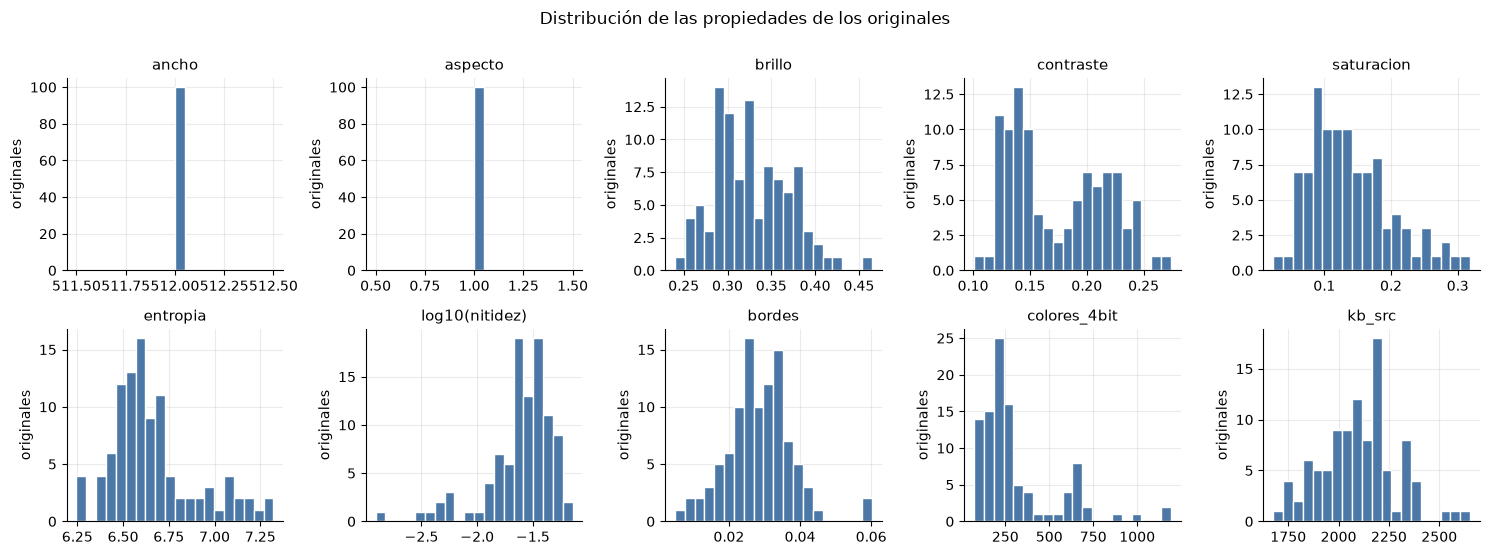

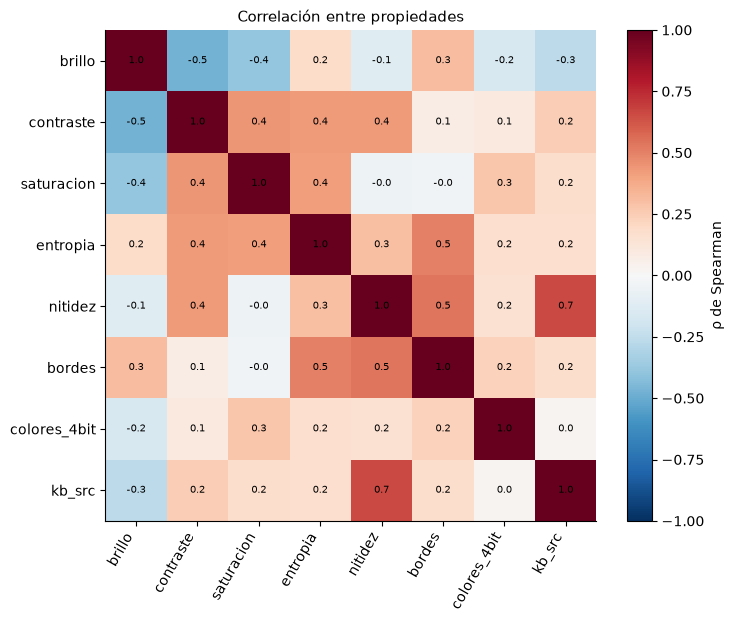

In [4]:
# [2. EDA] Histogramas de las propiedades de los originales.
# Por qué: detectar sesgos (fondo común, baja saturación) que afectarán a las representaciones de color y textura.
cols_h = [c for c in ["ancho", "aspecto", "brillo", "contraste", "saturacion", "entropia",
                      "nitidez", "bordes", "colores_4bit", "kb_src"] if c in props]
fig, axes = plt.subplots(2, 5, figsize=(15, 5.5))
for ax, c in zip(axes.ravel(), cols_h):
    v = props[c].values
    if c == "nitidez":
        v, etiqueta = np.log10(v + 1e-9), "log10(nitidez)"
    else:
        etiqueta = c
    ax.hist(v, bins=20, color="#4C78A8", edgecolor="white")
    ax.set_title(etiqueta); ax.set_ylabel("originales")
for ax in axes.ravel()[len(cols_h):]:
    ax.axis("off")
plt.suptitle("Distribución de las propiedades de los originales", y=1.0)
plt.tight_layout(); plt.savefig(DIR_RES / "eda_originales.png", dpi=150); plt.show()

# Correlación de Spearman entre propiedades: ¿miden cosas distintas o redundantes?
cs = props[[c for c in COLS_PROP if props[c].nunique() > 1]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(cs.values, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(cs))); ax.set_xticklabels(cs.columns, rotation=60, ha="right")
ax.set_yticks(range(len(cs))); ax.set_yticklabels(cs.columns); ax.grid(False)
for i in range(len(cs)):
    for j in range(len(cs)):
        ax.text(j, i, f"{cs.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="ρ de Spearman"); ax.set_title("Correlación entre propiedades")
plt.tight_layout(); plt.savefig(DIR_RES / "eda_correlacion.png", dpi=150); plt.show()

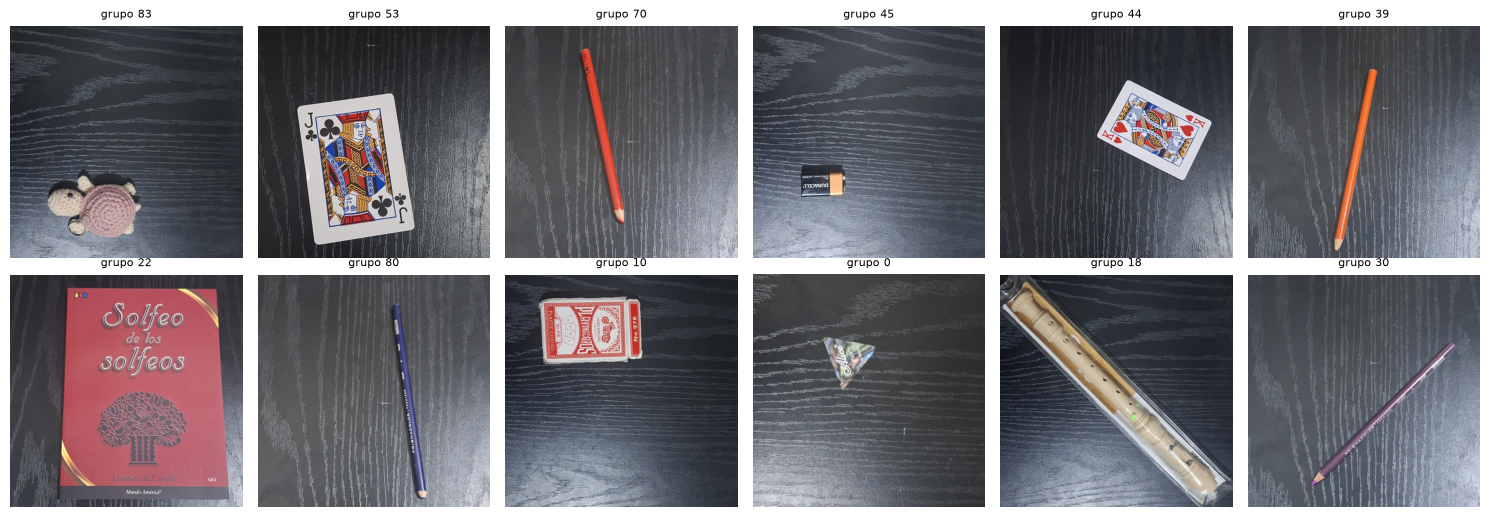

In [5]:
# [2. EDA] Muestra visual de originales: la inspección directa complementa los números.
# Muestra de originales
muestra = originales.sample(min(12, len(originales)), random_state=SEED)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
for ax, (_, r) in zip(axes.ravel(), muestra.iterrows()):
    ax.imshow(Image.open(DIR_ORIG / r.archivo)); ax.axis("off"); ax.set_title(f"grupo {r.group_id}", fontsize=8)
for ax in axes.ravel()[len(muestra):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

**Lectura.** La colección es muy homogénea: objetos sueltos (lápices, naipes, una pila, un libro, una flauta, peluches) fotografiados desde arriba sobre la misma mesa de madera oscura. Todas las imágenes originales eran de 2,992 × 2,992 px (≈ 2 MB) y se redujeron a 512 × 512. Son oscuras (brillo medio 0.33, rango 0.24–0.47) y poco saturadas (saturación media 0.14), con poca variación entre fotos (desviación del brillo 0.04).

Consecuencias para lo que sigue:
- Casi todo el fondo es idéntico entre fotos, así que lo que distingue una foto de otra es un objeto relativamente pequeño. Esto penaliza a las representaciones globales (pHash e histograma de color).
- Con una paleta tan estrecha, el histograma de color parte con poca capacidad para discriminar.
- Hay negativos difíciles reales (varios lápices, varios naipes), que reaparecen en el análisis de errores.

## 3. Variantes por aumento de datos

Cada variante hereda el `group_id` de su original. Las transformaciones se aplican siempre en un **orden canónico** (el de `CONFIG["transformaciones"]`: geométricas → color → JPEG), como en una cadena real de edición y exportación, y el manifiesto guarda el nombre y los parámetros exactos. Así, `recorte+brillo+jpeg` es una sola categoría y no seis órdenes distintos.

- **Geométricas:** recorte, rotación, reescalado.
- **Color:** brillo, contraste, saturación, tono y balance cálido/frío. Son las que ponen a prueba a los histogramas de color, que son invariantes a la geometría.
- **Compresión:** JPEG.

Las esquinas vacías de la rotación se manejan según `ROTACION_BORDE` (por defecto, recorte central en fotos y color del borde en figuras) para que un relleno negro no sirva de pista.

In [6]:
# [3. Preprocesamiento] Aumento de datos: genera las variantes de cada original y el manifiesto con sus parámetros.
# Por qué: la verdad de referencia es el group_id; las transformaciones se aplican en orden canónico
# (geométricas, color, JPEG) para que la etiqueta de cada variante sea reproducible. Azar con SEED + 1.
rng_var = np.random.default_rng(SEED + 1)
ROT_BORDE = ("color" if MODO == "sintetico" else "recortar") if ROTACION_BORDE == "auto" else ROTACION_BORDE
assert ROT_BORDE in ("recortar", "color", "negro"), "ROTACION_BORDE no válido"
assert all(t in CONFIG for t in CONFIG["transformaciones"]), "Falta el rango de alguna transformación"
assert CONFIG["n_transf_por_variante"] <= len(CONFIG["transformaciones"])

def color_borde(img):
    a = np.asarray(img.convert("RGB"))
    borde = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
    return tuple(int(v) for v in np.median(borde, axis=0))

# ── Operaciones puras (parámetros explícitos): las usan las variantes y la prueba de estrés ──
def op_recorte(img, fx, fy, ux=0.5, uy=0.5):
    w, h = img.size
    cw, ch = max(8, int(w*(1-fx))), max(8, int(h*(1-fy)))
    x0, y0 = int((w-cw)*ux), int((h-ch)*uy)
    return img.crop((x0, y0, x0+cw, y0+ch))

def op_rotacion(img, ang, fondo):
    if ROT_BORDE == "recortar":
        w, h = img.size
        a = math.radians(ang); c, s = abs(math.cos(a)), abs(math.sin(a))
        esc = min(1.0, w/(w*c + h*s), h/(w*s + h*c))          # mayor recorte central, misma proporción
        wr, hr = int(w*esc) - 2, int(h*esc) - 2
        if wr >= 32 and hr >= 32:
            rot = img.rotate(ang, expand=False, resample=Image.BICUBIC)
            izq, arr = (w-wr)//2, (h-hr)//2
            return rot.crop((izq, arr, izq+wr, arr+hr))
        relleno = fondo                                        # imagen demasiado pequeña
    else:
        relleno = fondo if ROT_BORDE == "color" else (0, 0, 0)
    return img.rotate(ang, expand=True, fillcolor=relleno, resample=Image.BICUBIC)

def op_reescalado(img, f):
    return img.resize((max(32, int(img.width*f)), max(32, int(img.height*f))), Image.LANCZOS)

def op_brillo(img, f):     return ImageEnhance.Brightness(img).enhance(f)
def op_contraste(img, f):  return ImageEnhance.Contrast(img).enhance(f)
def op_saturacion(img, f): return ImageEnhance.Color(img).enhance(f)

def op_tono(img, grados):
    hsv = np.asarray(img.convert("HSV")).astype(np.int16)
    hsv[..., 0] = (hsv[..., 0] + int(round(grados/360*256))) % 256
    return Image.fromarray(hsv.astype(np.uint8), "HSV").convert("RGB")

def op_balance(img, g_rojo, g_azul):
    a = np.asarray(img.convert("RGB")).astype(np.float32)
    a[..., 0] *= g_rojo; a[..., 2] *= g_azul
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))

def op_jpeg(img, q):
    buf = io.BytesIO(); img.save(buf, "JPEG", quality=int(q)); buf.seek(0)
    return Image.open(buf).convert("RGB")

# ── Muestreo de parámetros (variantes del dataset) ──
def signo(): return float(rng_var.choice([-1, 1]))

def t_recorte(img, fondo):
    fx, fy = rng_var.uniform(*CONFIG["recorte"], 2); ux, uy = rng_var.uniform(0, 1, 2)
    return op_recorte(img, fx, fy, ux, uy), dict(fx=round(float(fx), 3), fy=round(float(fy), 3))
def t_rotacion(img, fondo):
    ang = float(rng_var.uniform(*CONFIG["rotacion"]) * signo())
    return op_rotacion(img, ang, fondo), dict(grados=round(ang, 1))
def t_reescalado(img, fondo):
    f = float(rng_var.uniform(*CONFIG["reescalado"]))
    return op_reescalado(img, f), dict(factor=round(f, 3))
def t_factor(op, clave):
    def fn(img, fondo):
        f = float(rng_var.uniform(*CONFIG[clave]))
        return op(img, f), dict(factor=round(f, 3))
    return fn
def t_tono(img, fondo):
    gr = float(rng_var.uniform(*CONFIG["tono"]) * signo())
    return op_tono(img, gr), dict(grados=round(gr, 1))
def t_balance(img, fondo):
    s = float(rng_var.uniform(*CONFIG["balance"]) * signo())
    return op_balance(img, 1 + s, 1 - s), dict(intensidad=round(s, 3))
def t_jpeg(img, fondo):
    return img, dict(calidad=int(rng_var.integers(CONFIG["jpeg"][0], CONFIG["jpeg"][1] + 1)))   # se aplica al guardar

TRANSF = {"recorte": t_recorte, "rotacion": t_rotacion, "reescalado": t_reescalado,
          "brillo": t_factor(op_brillo, "brillo"), "contraste": t_factor(op_contraste, "contraste"),
          "saturacion": t_factor(op_saturacion, "saturacion"), "tono": t_tono,
          "balance": t_balance, "jpeg": t_jpeg}
ORDEN_TRANSF = list(CONFIG["transformaciones"])

for f in DIR_DATASET.glob("*"):          # evita mezclar corridas anteriores
    f.unlink()

filas = []
for _, fila in originales.iterrows():
    base = Path(fila.archivo).stem
    img0 = Image.open(DIR_ORIG / fila.archivo).convert("RGB")
    fondo = color_borde(img0)
    img0.save(DIR_DATASET / fila.archivo)
    filas.append(dict(archivo=fila.archivo, group_id=fila.group_id, tipo="original",
                      transformaciones="", parametros="{}"))
    for v in range(CONFIG["n_variantes"]):
        elegidas = [str(t) for t in rng_var.choice(ORDEN_TRANSF, size=CONFIG["n_transf_por_variante"], replace=False)]
        elegidas.sort(key=ORDEN_TRANSF.index)                  # orden canónico
        img, params, jpeg_q = img0.copy(), {}, None
        for t in elegidas:
            img, p = TRANSF[t](img, fondo)
            params[t] = p
            if t == "jpeg":
                jpeg_q = p["calidad"]
        if jpeg_q is not None:
            nombre = f"{base}_v{v}.jpg"; img.save(DIR_DATASET / nombre, quality=jpeg_q)
        else:
            nombre = f"{base}_v{v}.png"; img.save(DIR_DATASET / nombre)
        filas.append(dict(archivo=nombre, group_id=fila.group_id, tipo="variante",
                          transformaciones="+".join(elegidas), parametros=json.dumps(params)))

manifiesto = pd.DataFrame(filas)
for t in ORDEN_TRANSF:
    manifiesto[f"t_{t}"] = manifiesto.transformaciones.apply(lambda s: t in s.split("+"))
manifiesto["n_transf"] = manifiesto.transformaciones.apply(lambda s: 0 if s == "" else len(s.split("+")))
print(len(manifiesto), "imágenes en total")
print(manifiesto.transformaciones.replace("", "(original)").value_counts().head(15))

600 imágenes en total
transformaciones
(original)                       100
brillo+contraste+balance          12
rotacion+reescalado+tono          11
rotacion+saturacion+jpeg          11
rotacion+reescalado+contraste     10
recorte+reescalado+brillo         10
saturacion+balance+jpeg           10
reescalado+saturacion+jpeg        10
brillo+saturacion+jpeg             9
recorte+tono+jpeg                  9
reescalado+saturacion+tono         9
rotacion+contraste+jpeg            9
rotacion+brillo+balance            9
recorte+contraste+saturacion       9
recorte+rotacion+reescalado        8
Name: count, dtype: int64


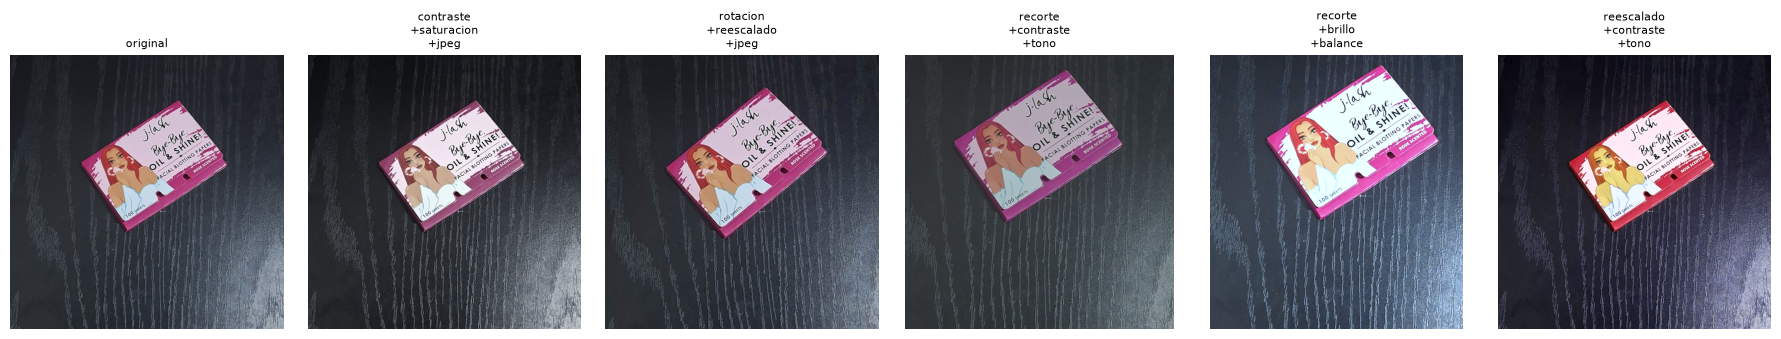

In [7]:
# [3. Preprocesamiento] Revisión visual de un grupo al azar (original + variantes).
# Revisión visual: un grupo al azar (original + variantes)
g_demo = int(np.random.default_rng(SEED).choice(manifiesto.group_id.unique()))
sub = manifiesto[manifiesto.group_id == g_demo]
fig, axes = plt.subplots(1, len(sub), figsize=(3*len(sub), 3.3))
for ax, (_, r) in zip(np.atleast_1d(axes), sub.iterrows()):
    ax.imshow(Image.open(DIR_DATASET / r.archivo)); ax.axis("off")
    ax.set_title((r.transformaciones or "original").replace("+", "\n+"), fontsize=8)
plt.tight_layout(); plt.show()

## 4. Análisis exploratorio de las variantes

Se verifica que el aumento de datos esté **balanceado** (todas las transformaciones aparecen con frecuencia similar y todos los grupos tienen el mismo tamaño) y que los parámetros realmente aplicados cubran los rangos configurados. También se mide cuánto cambian el tamaño y el peso del archivo, porque eso determina qué tan distinta es una variante de su original.

In [8]:
# [4. EDA de variantes] Tamaño, peso y área de cada variante respecto de su original.
# Por qué: comprobar que el aumento de datos quedó como se configuró.
def info_archivo(a):
    p = DIR_DATASET / a
    with Image.open(p) as im:
        w, h = im.size
    return w, h, p.stat().st_size / 1024

info = pd.DataFrame([info_archivo(a) for a in manifiesto.archivo], columns=["ancho", "alto", "kb"])
manifiesto = pd.concat([manifiesto, info], axis=1)
base_ = manifiesto[manifiesto.tipo == "original"].set_index("group_id")
manifiesto["ratio_area"] = (manifiesto.ancho * manifiesto.alto) / (manifiesto.group_id.map(base_.ancho) * manifiesto.group_id.map(base_.alto))
manifiesto["ratio_kb"] = manifiesto.kb / manifiesto.group_id.map(base_.kb)
manifiesto.to_csv(RAIZ / "manifiesto.csv", index=False)

var = manifiesto[manifiesto.tipo == "variante"].copy()
P = var.parametros.apply(json.loads)
def par(t, k): return P.apply(lambda d: d.get(t, {}).get(k, np.nan))
var["recorte_fx"], var["recorte_fy"] = par("recorte", "fx"), par("recorte", "fy")
var["rot_grados"], var["tono_grados"] = par("rotacion", "grados"), par("tono", "grados")
var["escala"], var["jpeg_q"] = par("reescalado", "factor"), par("jpeg", "calidad")
var["brillo_f"], var["contraste_f"] = par("brillo", "factor"), par("contraste", "factor")
var["saturacion_f"], var["balance_s"] = par("saturacion", "factor"), par("balance", "intensidad")

print("Tamaño de los grupos:", manifiesto.groupby("group_id").size().value_counts().to_dict())
print("\nFracción de variantes que incluyen cada transformación:")
print(var[[f"t_{t}" for t in ORDEN_TRANSF]].mean().round(3).rename(lambda s: s[2:]).to_string())
print("\nNúmero de transformaciones por variante:", var.n_transf.value_counts().to_dict())

Tamaño de los grupos: {6: 100}

Fracción de variantes que incluyen cada transformación:
recorte       0.346
rotacion      0.326
reescalado    0.344
brillo        0.310
contraste     0.316
saturacion    0.352
tono          0.340
balance       0.340
jpeg          0.326

Número de transformaciones por variante: {3: 500}


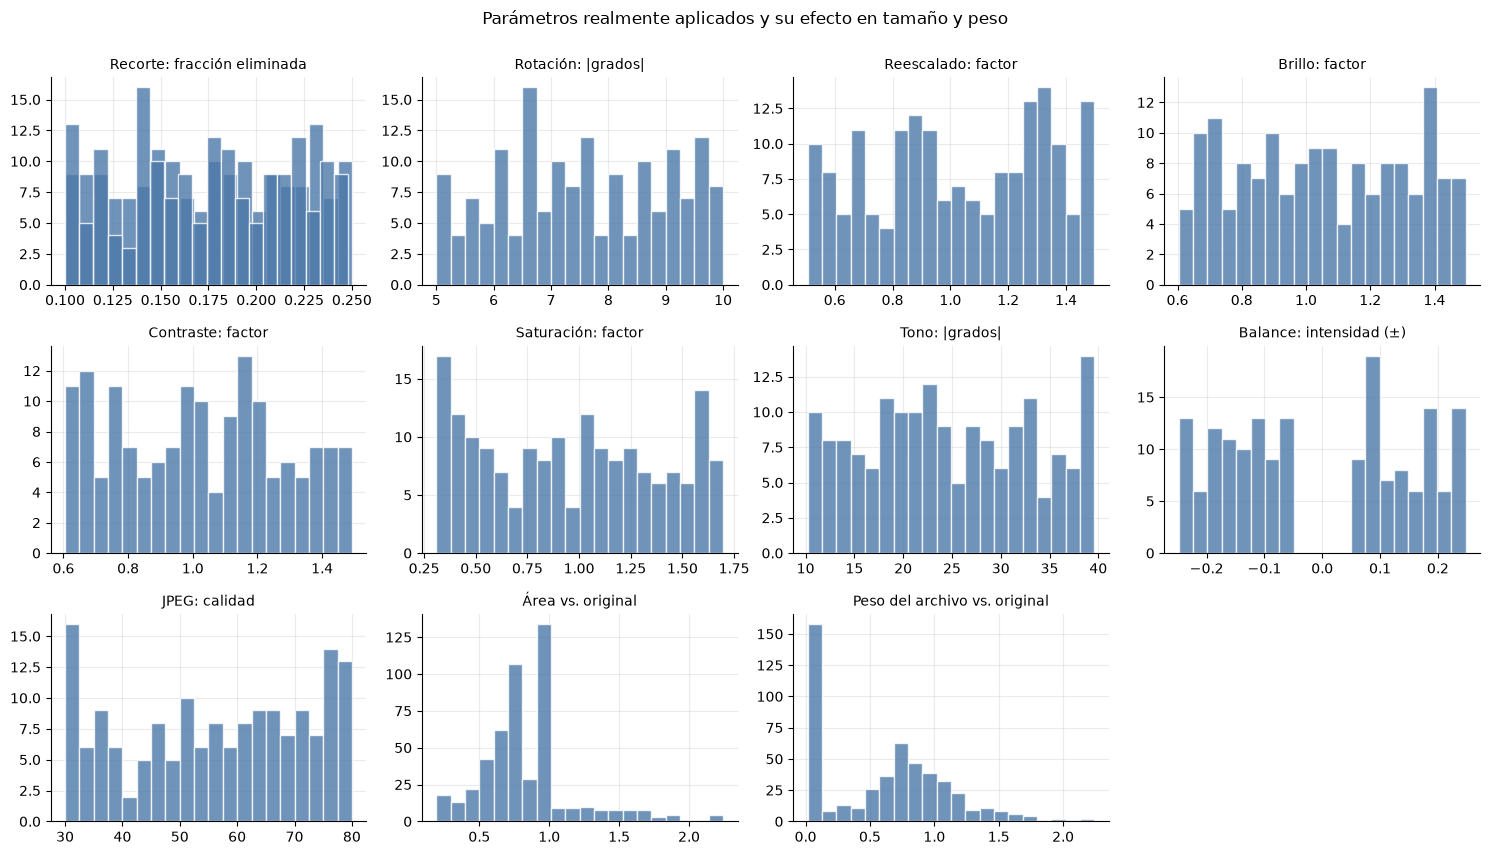

In [9]:
# [4. EDA de variantes] Distribución de los parámetros de cada transformación y balance entre transformaciones.
paneles = [("Recorte: fracción eliminada", ["recorte_fx", "recorte_fy"]), ("Rotación: |grados|", ["rot_grados"]),
           ("Reescalado: factor", ["escala"]), ("Brillo: factor", ["brillo_f"]),
           ("Contraste: factor", ["contraste_f"]), ("Saturación: factor", ["saturacion_f"]),
           ("Tono: |grados|", ["tono_grados"]), ("Balance: intensidad (±)", ["balance_s"]),
           ("JPEG: calidad", ["jpeg_q"]), ("Área vs. original", ["ratio_area"]), ("Peso del archivo vs. original", ["ratio_kb"])]
fig, axes = plt.subplots(3, 4, figsize=(15, 8.5))
for ax, (titulo, cols) in zip(axes.ravel(), paneles):
    vals = [var[c].abs().dropna().values if c in ("rot_grados", "tono_grados") else var[c].dropna().values for c in cols]
    if sum(len(v) for v in vals) == 0:
        ax.text(0.5, 0.5, "transformación inactiva", ha="center", va="center", transform=ax.transAxes, color="gray")
    else:
        for v in vals:
            ax.hist(v, bins=20, color="#4C78A8", edgecolor="white", alpha=0.8)
    ax.set_title(titulo, fontsize=10)
for ax in axes.ravel()[len(paneles):]:
    ax.axis("off")
plt.suptitle("Parámetros realmente aplicados y su efecto en tamaño y peso", y=1.0)
plt.tight_layout(); plt.savefig(DIR_RES / "eda_variantes.png", dpi=150); plt.show()

**Lectura.** El aumento de datos quedó balanceado: cada transformación aparece en 31–35 % de las variantes (brillo 31.0 %, saturación 35.2 %), todos los grupos tienen 6 imágenes (original + 5 variantes) y cada variante lleva exactamente 3 transformaciones. Con 9 transformaciones posibles, la mayoría de las variantes mezcla geometría, color y compresión, un escenario **más exigente** que el de un duplicado real, que típicamente tiene una o dos. Las exhaustividades de las secciones siguientes deben leerse como cotas para un caso adverso.

## Decisiones que informó la exploración

| Hallazgo de la exploración | Decisión tomada |
|---|---|
| Colección homogénea: objetos sueltos, mucha área oscura, baja saturación y fondo común (secciones 2 y 7) | Se anticipa que color y textura discriminarán poco; se agregan transformaciones de color y se evalúa también sin umbral (sección 9). |
| Rotar con relleno negro creaba un borde artificial que pHash explotaba (sección 4) | Rotaciones con recorte central (`ROTACION_BORDE="recortar"`), sin esquinas vacías. |
| Prevalencia de duplicados de 0.83 % entre pares (sección 5) | Se reporta precisión/exhaustividad/F1 y AP en lugar de exactitud, y se compara con el azar (≈ prevalencia). |
| Originales casi iguales entre sí harían pasar por falso positivo a un par que en realidad es duplicado | Filtro `DEDUP_UMBRAL` entre originales. |
| Cada variante comparte origen con otras (mismas fotos en varios pares) | Folds por `group_id` y bootstrap por grupo, no por par. |
| Las transformaciones se encadenan en cada variante | Orden canónico y tabla marginal por transformación (sección 10), más prueba de estrés de una a la vez (sección 15). |

## 5. Folds por grupo, tabla de pares y pruebas de sanidad

Los folds se asignan por `group_id` (estratificados por categoría): un original y sus variantes nunca quedan en folds distintos. Un par es positivo si comparte `group_id`. Para calibrar se usan solo pares con ambas imágenes en entrenamiento, y para evaluar solo pares con ambas imágenes en el fold de prueba.

El problema está **muy desbalanceado** (los positivos son una fracción pequeña de todos los pares), así que la exactitud (*accuracy*) no sirve: se usan precisión, exhaustividad y métricas que no dependen de un umbral (AP, AUC).

In [10]:
# [5. Partición] Folds por grupo (StratifiedGroupKFold), tabla de pares y pruebas de sanidad.
# Por qué: un original y sus variantes nunca quedan en folds distintos, así no hay fuga entre entrenamiento y prueba.
# Los pares se construyen sobre todas las imágenes; en cada fold solo se evalúan pares con ambas imágenes en prueba.
man = manifiesto.merge(originales[["group_id", "forma"]], on="group_id").reset_index(drop=True)
n = len(man)
rutas = [DIR_DATASET / a for a in man.archivo]          # mismo orden que `man`

man["fold"] = -1
sgkf = StratifiedGroupKFold(n_splits=K, shuffle=True, random_state=SEED)
for f, (_, te) in enumerate(sgkf.split(man, man.forma, man.group_id)):
    man.loc[te, "fold"] = f

g, fo, fm = man.group_id.values, man.fold.values, man.forma.values
tipo, trf = man.tipo.values, man.transformaciones.fillna("").values
I, J = np.triu_indices(n, 1)
pares = pd.DataFrame(dict(i=I, j=J, duplicado=(g[I] == g[J]), misma_forma=(fm[I] == fm[J]),
                          tipo_par=np.where((tipo[I] == "original") | (tipo[J] == "original"),
                                            "original-variante", "variante-variante")))
y_all = pares.duplicado.values
PREVALENCIA = y_all.mean()
print(f"{len(pares):,} pares | {y_all.sum():,} positivos ({100*PREVALENCIA:.2f} %)")
print("Positivos por tipo de par:", pares[pares.duplicado].tipo_par.value_counts().to_dict())
print("Imágenes por fold:", np.bincount(fo).tolist(), "| grupos por fold:", man.groupby("fold").group_id.nunique().tolist())

def mejor_umbral(d, y):
    # umbral de distancia que maximiza F1 (positivo si d <= umbral)
    p, r, t = precision_recall_curve(y, -d)
    f1 = 2 * p * r / (p + r + 1e-12)
    return -t[np.argmax(f1[:-1])]

def evaluar(D, nombre):
    d_all, mf = D[I, J], pares.misma_forma.values
    filas = []
    for f in range(K):
        train = (fo[I] != f) & (fo[J] != f)
        test  = (fo[I] == f) & (fo[J] == f)
        u = mejor_umbral(d_all[train], y_all[train])
        pred, y = d_all[test] <= u, y_all[test]
        tp = (pred & y).sum()
        filas.append(dict(representacion=nombre, fold=f, umbral=u,
                          precision=tp / max(pred.sum(), 1), exhaustividad=tp / y.sum(),
                          fp=int((pred & ~y).sum()), fp_misma_forma=int((pred & ~y & mf[test]).sum())))
    return pd.DataFrame(filas)

# ── Pruebas de sanidad ──
tam = man.groupby("group_id").size()
assert man.groupby("group_id").fold.nunique().max() == 1, "Un grupo quedó repartido entre folds (fuga de datos)"
assert tam.nunique() == 1, "Los grupos no tienen el mismo tamaño"
assert y_all.sum() == int((tam * (tam - 1) // 2).sum()), "Número de pares positivos inesperado"
assert sorted(man.fold.unique()) == list(range(K)), "Algún fold quedó vacío"
print("Pruebas de sanidad de datos: OK (sin fuga entre folds, grupos completos, pares positivos esperados)")

179,700 pares | 1,500 positivos (0.83 %)
Positivos por tipo de par: {'variante-variante': 1000, 'original-variante': 500}
Imágenes por fold: [120, 120, 120, 120, 120] | grupos por fold: [20, 20, 20, 20, 20]
Pruebas de sanidad de datos: OK (sin fuga entre folds, grupos completos, pares positivos esperados)


**Lectura.** Hay 179,700 pares y solo 1,500 son duplicados (0.83 %): 500 entre original y variante y 1,000 entre dos variantes (que acumulan entre 3 y 6 transformaciones). Con esta prevalencia, decir siempre «no duplicado» da una exactitud de ≈ 99 % y una AP de azar de 0.008, por eso se evalúa con precisión, exhaustividad, AP y mAP y no con exactitud. Cada fold de prueba tiene 20 grupos (120 imágenes, 300 pares positivos y 6,840 negativos), así que las métricas por fold son ruidosas, lo que explica las desviaciones grandes más adelante.

## Control de fugas de datos

- **Partición por grupo.** `StratifiedGroupKFold` (K=5) asigna cada original con todas sus variantes al mismo fold; no hay imágenes del mismo grupo en entrenamiento y prueba.
- **Umbral solo con entrenamiento.** En cada fold el umbral (y el nivel de precisión fija) se calibra con los pares donde ambas imágenes están en entrenamiento; se evalúa con los pares donde ambas están en prueba. Los pares mixtos no se usan.
- **Agrupamiento.** El corte del dendrograma se elige en entrenamiento y se aplica a prueba.
- **Fusión sin etiquetas.** Las distancias se normalizan con su mediana global; no interviene la verdad de referencia.
- **Propiedades de imagen.** Se usan solo para describir (secciones 2 y 16), nunca como variables del modelo.
- **Hiperparámetros.** Los valores base se fijaron antes de ver los resultados; la sección 13 los varía después y es solo descriptiva (no se elige la mejor configuración con ella).
- **ResNet-50 preentrenada, sin fine-tuning.** No hay entrenamiento que pueda filtrar información de prueba.
- **Umbral operativo** (secciones 15 y 18): mediana de los umbrales calibrados en los folds.

## 6. Representaciones, distancias y costo

| Representación | Qué captura | Distancia |
|---|---|---|
| pHash | estructura de baja frecuencia (DCT) | Hamming |
| Histograma de color (RGB) | distribución de color, sin geometría | Hellinger |
| LBP uniforme | micro-textura en gris | Hellinger |
| ResNet-50 (avgpool) | contenido semántico | Coseno |

Las características se guardan en `cache/` con una **huella** del conjunto de imágenes y de los hiperparámetros: si cambias las variantes o la configuración, el caché anterior se ignora solo. Además se **mide el costo** de cada representación (tiempo de extracción por imagen, dimensión y tiempo por comparación), que es el otro eje del compromiso costo/desempeño.

In [11]:
# [6. Representaciones] Extractores (pHash, histograma de color, LBP, ResNet-50) y funciones de distancia.
# Por qué: cuatro representaciones de costo creciente; ResNet-50 es preentrenada y no se ajusta (sin fine-tuning).
# Los vectores se guardan en caché con una huella de datos y parámetros para no mezclar corridas distintas.
def cargar(r):
    return Image.open(r).convert("RGB")

def extraer_phash(imgs, hash_size=8):
    return np.array([imagehash.phash(im, hash_size=hash_size).hash.flatten() for im in imgs], dtype=np.uint8)

def extraer_color(imgs, bins=None):
    bins = bins or BINS_COLOR
    out = []
    for im in imgs:
        a = np.asarray(im.convert("RGB")).reshape(-1, 3)
        h, _ = np.histogramdd(a, bins=(bins,)*3, range=((0, 256),)*3)
        h = h.flatten(); out.append(h / h.sum())
    return np.array(out)

def extraer_lbp(imgs, P=None, R=None, lado=None):
    P, R, lado = P or LBP_P, R or LBP_R, lado or LBP_LADO
    out = []
    for im in imgs:
        gris = np.asarray(im.convert("L").resize((lado, lado)))
        l = local_binary_pattern(gris, P, R, method="uniform")
        h, _ = np.histogram(l, bins=P + 2, range=(0, P + 2))
        out.append(h / h.sum())
    return np.array(out)

_RESNET = {}
def _cargar_resnet():
    if "m" not in _RESNET:
        import torch, torchvision
        from torchvision import transforms as T
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.DEFAULT)
        m.fc = torch.nn.Identity(); m.eval().to(dev)
        tf = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
        _RESNET.update(m=m, tf=tf, dev=dev, torch=torch)
    return _RESNET

def extraer_resnet(imgs, batch=64):
    R = _cargar_resnet(); torch = R["torch"]
    out = []
    with torch.no_grad():
        for k in range(0, len(imgs), batch):
            x = torch.stack([R["tf"](im.convert("RGB")) for im in imgs[k:k+batch]]).to(R["dev"])
            out.append(R["m"](x).cpu().numpy())
    return np.vstack(out)

def extraer_desde_rutas(extractor, rutas_, chunk=64, **kw):
    # lee las imágenes por bloques para no cargarlas todas en memoria
    return np.vstack([extractor([cargar(r) for r in rutas_[k:k+chunk]], **kw) for k in range(0, len(rutas_), chunk)])

def dist_hamming(X, Y=None):   Y = X if Y is None else Y; return cdist(X, Y, "hamming") * X.shape[1]
def dist_hellinger(X, Y=None): Y = X if Y is None else Y; return cdist(np.sqrt(X), np.sqrt(Y), "euclidean")
def dist_coseno(X, Y=None):    Y = X if Y is None else Y; return cdist(X, Y, "cosine")

def fila_hamming(A, B):   return (A != B).sum(1).astype(float)
def fila_hellinger(A, B): return np.linalg.norm(np.sqrt(A) - np.sqrt(B), axis=1)
def fila_coseno(A, B):    return 1 - (A * B).sum(1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1))

EXTRACTORES = {"pHash": extraer_phash, "Color": extraer_color, "LBP": extraer_lbp}
if USAR_RESNET:
    EXTRACTORES["ResNet"] = extraer_resnet
DIST = {"pHash": dist_hamming, "Color": dist_hellinger, "LBP": dist_hellinger, "ResNet": dist_coseno}
DIST_FILA = {"pHash": fila_hamming, "Color": fila_hellinger, "LBP": fila_hellinger, "ResNet": fila_coseno}

# huella del conjunto de imágenes: si cambian las variantes, el caché anterior no se reutiliza
HUELLA = hashlib.md5("|".join((man.archivo + man.parametros + man.kb.round(2).astype(str)).tolist()).encode()).hexdigest()[:10]
PARAMS_REP = {"pHash": "h8", "Color": f"b{BINS_COLOR}", "LBP": f"p{LBP_P}r{LBP_R}l{LBP_LADO}", "ResNet": "rn50"}

def preparar(D):
    D = np.clip((D + D.T) / 2, 0, None).copy()
    np.fill_diagonal(D, 0)
    return D

FEATS, matrices = {}, {}
for nombre, ext in EXTRACTORES.items():
    f = DIR_CACHE / f"{nombre}_{PARAMS_REP[nombre]}_{HUELLA}.npy"
    if f.exists() and len(np.load(f)) == n:
        X = np.load(f)
    else:
        X = extraer_desde_rutas(ext, rutas); np.save(f, X)
    FEATS[nombre] = X
    matrices[nombre] = preparar(DIST[nombre](X))
    print(f"{nombre:7s} características: {X.shape}")
ORDEN = list(matrices)

# ── Sanidad de las matrices de distancia ──
for nm, D in matrices.items():
    assert np.isfinite(D).all(), f"{nm}: hay distancias no finitas"
    assert np.allclose(D, D.T) and np.allclose(np.diag(D), 0), f"{nm}: no es simétrica o la diagonal no es cero"
    m_ = min(6, n - 1)                                      # la distancia por filas debe coincidir con la matricial
    assert np.allclose(DIST_FILA[nm](FEATS[nm][:m_], FEATS[nm][1:m_+1]),
                       DIST[nm](FEATS[nm][:m_+1])[np.arange(m_), np.arange(1, m_+1)], atol=1e-5), f"{nm}: distancia por filas inconsistente"
print("Pruebas de sanidad de las matrices: OK")

# ¿Qué tan parecidos son entre sí los originales distintos? (dificultad de los negativos)
if "pHash" in matrices:
    io_ = np.where(tipo == "original")[0]
    Do = matrices["pHash"][np.ix_(io_, io_)]; np.fill_diagonal(Do, np.inf)
    print(f"Originales distintos con pHash ≤ {DEDUP_UMBRAL if DEDUP_UMBRAL is not None else 6}:",
          int((Do <= (DEDUP_UMBRAL if DEDUP_UMBRAL is not None else 6)).sum() // 2), "pares")

pHash   características: (600, 64)
Color   características: (600, 512)
LBP     características: (600, 10)
ResNet  características: (600, 2048)
Pruebas de sanidad de las matrices: OK
Originales distintos con pHash ≤ 6: 0 pares


In [12]:
# [6. Costo] Tiempo por imagen, tamaño del vector y costo por comparación de cada representación.
# Muestra aleatoria con SEED + 3. Nota: ResNet puede correr en GPU y las demás en CPU (ver la salvedad en la lectura).
def medir_costo(n_muestra=N_COSTO):
    rng_c = np.random.default_rng(SEED + 3)
    idx = rng_c.choice(n, size=min(n_muestra, n), replace=False)
    imgs = [cargar(rutas[i]) for i in idx]
    filas = []
    for nombre, ext in EXTRACTORES.items():
        ext(imgs[:4])                                              # calentamiento (carga del modelo, cachés)
        t0 = time.perf_counter(); ext(imgs); t_ext = (time.perf_counter() - t0) / len(imgs)
        X = FEATS[nombre]; m_ = min(300, len(X))
        t0 = time.perf_counter(); DIST[nombre](X[:m_]); t_dist = (time.perf_counter() - t0) / (m_ * m_)
        filas.append(dict(representacion=nombre, dimension=X.shape[1],
                          bytes_por_imagen=X.shape[1] / 8 if nombre == "pHash" else X.shape[1] * 4,
                          ms_por_imagen=1e3 * t_ext, us_por_par=1e6 * t_dist))
    return pd.DataFrame(filas).set_index("representacion")

costo = medir_costo()
costo["seg_totales"] = costo.ms_por_imagen * n / 1000
if "dev" in _RESNET:
    print("ResNet-50 corrió en:", _RESNET["dev"])
costo.round(3)

ResNet-50 corrió en: cuda


,dimension,bytes_por_imagen,ms_por_imagen,us_por_par,seg_totales
representacion,,,,,
pHash,64,8.0,0.994,0.015,0.596
Color,512,2048.0,7.159,0.124,4.296
LBP,10,40.0,2.626,0.003,1.575
ResNet,2048,8192.0,3.690,0.475,2.214


**Lectura.**

| Representación | ms/imagen | Dimensión | Bytes/imagen | µs por par |
|---|---|---|---|---|
| pHash | 1.02 | 64 | 8 | 0.015 |
| LBP | 2.70 | 10 | 40 | 0.003 |
| ResNet | 3.67 | 2,048 | 8,192 | 0.503 |
| Color | 7.58 | 512 | 2,048 | 0.134 |

- **Salvedad de hardware.** ResNet corrió en GPU (`cuda`) y las demás en CPU, así que los milisegundos no son comparables entre sí. En CPU ResNet sería más lento (no se midió).
- El histograma de color es el más lento, probablemente por la implementación (`histogramdd` sobre los 262,144 píxeles de cada imagen) y no por un costo intrínseco.
- Lo que no depende del hardware: pHash ocupa 8 bytes por imagen y ResNet 8,192 (1,024 veces más), y comparar dos vectores cuesta unas 33 veces más con ResNet. La comparación de todos contra todos crece con el cuadrado del número de fotos, así que en colecciones grandes ese costo pesa más que el de extracción.

## 7. Exploración del espacio de características (t-SNE)

Proyección en 2D de cada representación usando **su propia distancia** (matriz precalculada). Se resaltan algunos grupos de duplicados (color) sobre el resto (gris); la estrella marca el original. Si una representación es buena, los puntos de un mismo grupo aparecen juntos. Es una herramienta **exploratoria**: las distancias en t-SNE no deben leerse literalmente.

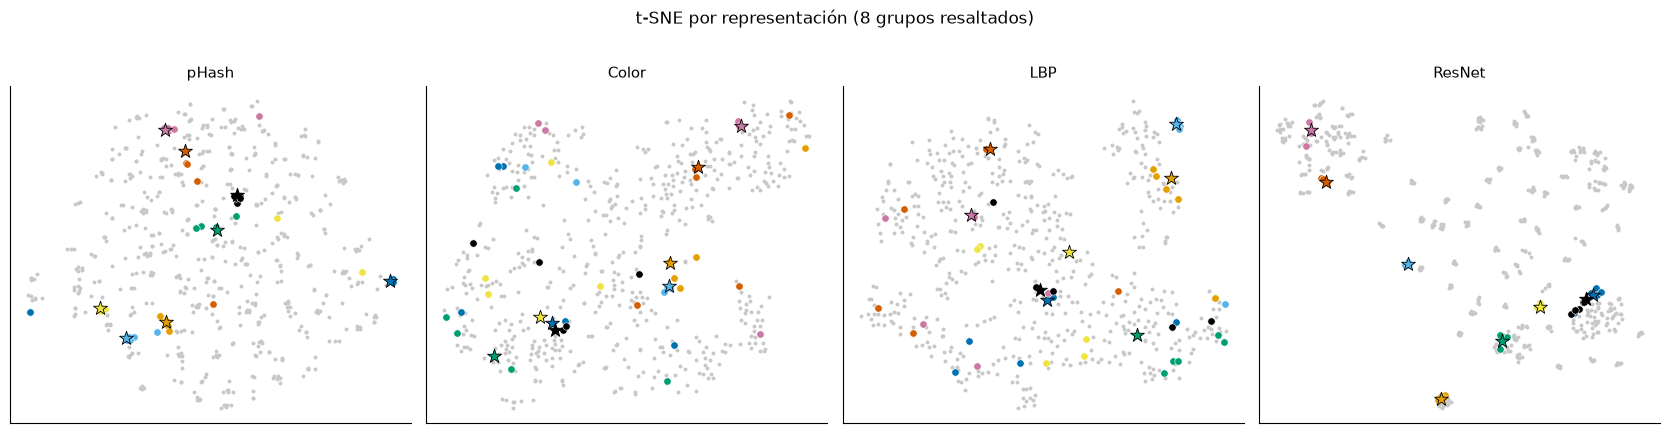

In [13]:
# [7. t-SNE] Proyección 2D de cada representación para explorar la separación entre grupos (solo exploración).
# Se resaltan grupos elegidos al azar (SEED) y los mismos en los cuatro paneles.
OKABE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]
rng_t = np.random.default_rng(SEED)
grupos_res = rng_t.choice(np.unique(g), size=min(TSNE_GRUPOS, len(np.unique(g))), replace=False)
perp = float(min(30, max(5, (n - 1) // 4)))

fig, axes = plt.subplots(1, len(ORDEN), figsize=(4.2 * len(ORDEN), 4.2))
for ax, nm in zip(np.atleast_1d(axes), ORDEN):
    Y = TSNE(n_components=2, metric="precomputed", init="random", perplexity=perp,
             random_state=SEED).fit_transform(matrices[nm])
    ax.scatter(Y[:, 0], Y[:, 1], s=8, c="#C8C8C8", linewidths=0)
    for k, gr in enumerate(grupos_res):
        m_ = g == gr
        ax.scatter(Y[m_, 0], Y[m_, 1], s=28, color=OKABE[k % len(OKABE)], linewidths=0.4, edgecolors="white")
        o_ = m_ & (tipo == "original")
        ax.scatter(Y[o_, 0], Y[o_, 1], s=110, marker="*", color=OKABE[k % len(OKABE)], edgecolors="black", linewidths=0.6)
    ax.set_title(nm); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.suptitle(f"t-SNE por representación ({len(grupos_res)} grupos resaltados)", y=1.02)
plt.tight_layout(); plt.savefig(DIR_RES / "tsne.png", dpi=150, bbox_inches="tight"); plt.show()

**Lectura.** (Los 8 grupos resaltados se eligen al azar y son los mismos en los cuatro paneles.) En ResNet las fotos forman islas compactas, muchas del tamaño de un grupo de 6, y varios grupos resaltados quedan juntos aunque otros se separan. En pHash algunos grupos también quedan juntos, pero entre pHash, color y LBP los puntos forman una nube más uniforme y hay grupos más dispersos. Es coherente con las métricas de las secciones 9 a 12. t-SNE es solo exploratorio: no sirve para comparar distancias ni para medir la calidad.

## Línea base y comparación justa

- **Línea base: pHash.** Es el método estándar y barato para duplicados; las demás representaciones se leen frente a él.
- **Mismas condiciones para todos.** Mismas imágenes, mismos folds, mismos pares, mismo protocolo de calibración y las mismas métricas. Solo cambia la representación y su distancia natural (Hamming, Hellinger, coseno).
- **Sin ventajas de ajuste.** ResNet-50 no se ajusta a estos datos y los demás métodos usan hiperparámetros base fijados de antemano.
- **Variabilidad.** Desviación entre folds y bootstrap por grupos; las diferencias entre métodos se juzgan con intervalos pareados.
- **Salvedad.** Los tiempos de ResNet (GPU) y los de las demás (CPU) no son directamente comparables; la comparación de almacenamiento y de costo por par sí lo es.

## 8. Evaluación sobre pares de duplicados

Umbral calibrado con F1 máximo en entrenamiento; precisión y exhaustividad medidas en el fold de prueba. Es **un solo punto de operación**: la sección 9 evalúa sin depender del umbral.

In [14]:
# [8. Evaluación] Precisión y exhaustividad sobre pares, por fold.
# Por qué: el umbral se calibra solo con los pares de entrenamiento de cada fold y se aplica a los de prueba.
res = pd.concat([evaluar(D, nombre) for nombre, D in matrices.items()])
cols_fp = ["fp_misma_forma"] if HAY_CATEGORIAS else ["fp"]
res_pares = (res.groupby("representacion")[["precision", "exhaustividad"] + cols_fp]
               .agg(["mean", "std"]).loc[ORDEN].round(3))
UMBRAL_OP = res.groupby("representacion").umbral.median()      # umbral operativo de cada representación
res_pares

precision        exhaustividad           fp        
                    mean    std          mean    std  mean     std
representacion                                                    
pHash              0.904  0.092         0.480  0.053  17.2  18.102
Color              0.474  0.166         0.120  0.022  51.4  39.412
LBP                0.478  0.134         0.103  0.020  38.0  22.417
ResNet             0.863  0.114         0.617  0.028  32.8  31.539

**Lectura.** Con el umbral calibrado por F1, ResNet logra el mejor equilibrio (precisión 0.863, exhaustividad 0.617; F1 0.719 en la sección 17). pHash prioriza la precisión (0.904) a costa de la exhaustividad (0.480). Color y LBP no pasan de precisión ≈ 0.48 y exhaustividad ≈ 0.10–0.12: de cada dos pares que declaran duplicados, uno es falso. Los falsos positivos medios por fold van de 17 (pHash) a 51 (color) sobre 6,840 pares negativos. La precisión varía mucho entre folds (desviación 0.09–0.17) porque cada fold tiene solo 300 positivos; la exhaustividad de ResNet es más estable (desviación 0.028).

## 9. Diagnóstico sin umbral y punto de operación seguro

- **Distribuciones de distancia.** Cuanto menos se traslapan positivos y negativos, más separable es el problema. `d′` resume la separación (diferencia de medias entre desviación típica combinada).
- **ROC-AUC y AP (precisión promedio).** Miden todo el ranking sin elegir umbral. La referencia de azar es AUC = 0.5 y AP = prevalencia.
- **Curvas PR.** El marcador es el punto de operación de la sección 8.
- **Exhaustividad a precisión fija.** Para unificar carpetas sin perder fotos conviene operar con precisión ≥ 95 % (o 99 %): se calibra el umbral que maximiza la exhaustividad respetando esa precisión.

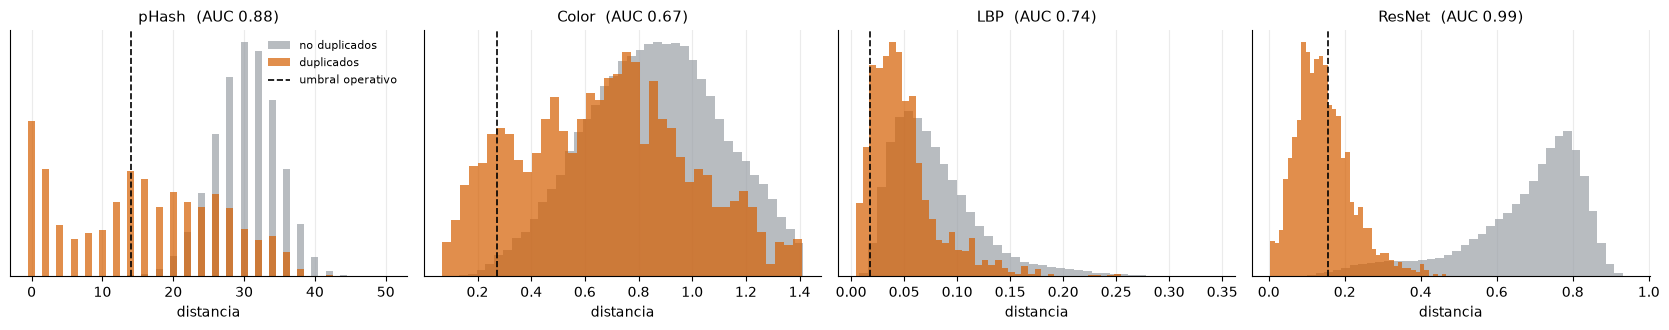

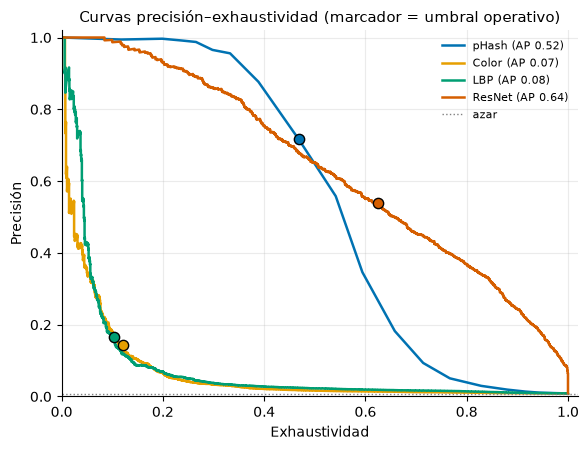

,AUC,AP,d_prima,mediana_pos,mediana_neg
pHash,0.882,0.517,1.761,16.000,30.000
Color,0.674,0.066,0.652,0.681,0.862
LBP,0.738,0.080,0.774,0.043,0.071
ResNet,0.992,0.638,4.208,0.135,0.718
(azar),0.500,0.008,0.000,NaN,NaN


In [15]:
# [9. Diagnóstico] Métricas sin umbral: ROC-AUC, AP, d′ y distancias medianas de pares duplicados y no duplicados.
def diagnostico(D):
    d = D[I, J]; pos, neg = d[y_all], d[~y_all]
    sd = np.sqrt(0.5 * (pos.var() + neg.var()))
    return dict(AUC=roc_auc_score(y_all, -d), AP=average_precision_score(y_all, -d),
                d_prima=(neg.mean() - pos.mean()) / sd, mediana_pos=np.median(pos), mediana_neg=np.median(neg))

diag = pd.DataFrame({nm: diagnostico(D) for nm, D in matrices.items()}).T.loc[ORDEN]
diag.loc["(azar)"] = dict(AUC=0.5, AP=PREVALENCIA, d_prima=0.0, mediana_pos=np.nan, mediana_neg=np.nan)
fpr_op = {nm: float((matrices[nm][I, J][~y_all] <= UMBRAL_OP[nm]).mean()) for nm in ORDEN}

fig, axes = plt.subplots(1, len(ORDEN), figsize=(4.2 * len(ORDEN), 3.4))
for ax, nm in zip(np.atleast_1d(axes), ORDEN):
    d = matrices[nm][I, J]
    bins = np.arange(-0.5, d.max() + 1.5) if nm == "pHash" else 40
    ax.hist(d[~y_all], bins=bins, density=True, color="#9AA0A6", alpha=0.7, label="no duplicados")
    ax.hist(d[y_all], bins=bins, density=True, color="#D55E00", alpha=0.7, label="duplicados")
    ax.axvline(UMBRAL_OP[nm], color="black", lw=1.2, ls="--", label="umbral operativo")
    ax.set_title(f"{nm}  (AUC {diag.loc[nm, 'AUC']:.2f})"); ax.set_xlabel("distancia"); ax.set_yticks([])
np.atleast_1d(axes)[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(DIR_RES / "distribuciones_distancia.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6, 4.6))
for nm in ORDEN:
    d = matrices[nm][I, J]
    p, r, _ = precision_recall_curve(y_all, -d)
    ax.plot(r, p, color=COLOR_REP.get(nm, "gray"), lw=1.8, label=f"{nm} (AP {diag.loc[nm, 'AP']:.2f})")
    pred = d <= UMBRAL_OP[nm]
    if pred.sum():
        ax.scatter([(pred & y_all).sum() / y_all.sum()], [(pred & y_all).sum() / pred.sum()],
                   s=55, color=COLOR_REP.get(nm, "gray"), edgecolors="black", zorder=3)
ax.axhline(PREVALENCIA, color="gray", ls=":", lw=1, label="azar")
ax.set_xlabel("Exhaustividad"); ax.set_ylabel("Precisión"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
ax.set_title("Curvas precisión–exhaustividad (marcador = umbral operativo)"); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(DIR_RES / "curvas_pr.png", dpi=150); plt.show()
diag.round(3)

In [16]:
# [9. Punto de operación seguro] Exhaustividad máxima exigiendo precisión mínima (P_MIN) en entrenamiento.
# Por qué: borrar una foto distinta es peor que dejar un duplicado.
def evaluar_precision_fija(D, nombre, p_min):
    d_all, filas = D[I, J], []
    for f in range(K):
        train = (fo[I] != f) & (fo[J] != f); test = (fo[I] == f) & (fo[J] == f)
        p, r, t = precision_recall_curve(y_all[train], -d_all[train])
        ok = np.where(p[:-1] >= p_min)[0]
        u = -t[ok[np.argmax(r[ok])]] if len(ok) else -np.inf      # sin umbral factible: no predice nada
        pred, y = d_all[test] <= u, y_all[test]; tp = (pred & y).sum()
        filas.append(dict(representacion=nombre, p_min=p_min, fold=f, factible=bool(len(ok)),
                          precision=tp / pred.sum() if pred.sum() else np.nan, exhaustividad=tp / y.sum()))
    return pd.DataFrame(filas)

res_pf = pd.concat([evaluar_precision_fija(D, nm, pm) for pm in P_MIN for nm, D in matrices.items()])
tab_pf = (res_pf.groupby(["p_min", "representacion"])[["exhaustividad", "precision"]].agg(["mean", "std"])
               .round(3))
print("Con pocos positivos por fold, la precisión ≥ 99 % es muy ruidosa: interpreta con cautela.")
tab_pf

Con pocos positivos por fold, la precisión ≥ 99 % es muy ruidosa: interpreta con cautela.


exhaustividad        precision       
                              mean    std      mean    std
p_min representacion                                      
0.95  Color                  0.007  0.006     1.000  0.000
      LBP                    0.008  0.007     0.900  0.224
      ResNet                 0.209  0.073     0.982  0.041
      pHash                  0.333  0.028     0.989  0.017
0.99  Color                  0.007  0.006     1.000  0.000
      LBP                    0.008  0.007     1.000  0.000
      ResNet                 0.127  0.047     1.000  0.000
      pHash                  0.230  0.019     0.995  0.012

**Lectura.**
- **Separabilidad.** ResNet separa casi por completo duplicados de no duplicados (AUC 0.992, d′ 4.2; distancia mediana 0.135 frente a 0.718). pHash separa bien pero con traslape (AUC 0.882, d′ 1.8; 16 frente a 30 bits de diferencia). Color (AUC 0.674) y LBP (0.738) apenas superan el azar (0.5); su AP (0.066 y 0.080) es 8–10 veces la de azar (0.008) pero muy baja en términos absolutos.
- **Punto de operación seguro.** Exigiendo precisión ≥ 95 %, la mejor exhaustividad es la de **pHash (0.333)** y no la de ResNet (0.209); con ≥ 99 % es 0.230 frente a 0.127 (cifra ruidosa). Color y LBP quedan en ≈ 0.01: no sirven para borrar duplicados sin riesgo. Una explicación probable, que se ve en la sección 18, es que ResNet confunde fotos distintas del mismo tipo de objeto (naipes) con distancias tan bajas como las de duplicados reales, lo que lo penaliza justo con umbrales estrictos.
- **AUC frente a AP en ResNet.** AUC 0.992 pero AP global 0.638: con solo 0.83 % de positivos, unos pocos falsos positivos de distancia baja bastan para bajar la precisión.

## 10. Exhaustividad por tipo de transformación

Cada par positivo `original–variante` se etiqueta con las transformaciones de su variante, y se calcula la exhaustividad **marginal**: de todos los pares cuya variante incluye la transformación X, qué fracción detecta cada representación (con el umbral calibrado en entrenamiento). Como cada variante combina varias transformaciones, el efecto de una sola queda mezclado con las demás; **el efecto aislado se mide en la prueba de estrés (sección 15)**.

También se desglosa por tipo de par (`variante-variante` acumula dos cadenas de transformaciones) y por número de transformaciones involucradas.

In [17]:
# [10. Por transformación] Exhaustividad de los pares positivos según la transformación aplicada a alguna de sus imágenes.
pos = np.where(y_all)[0]
ip, jp = I[pos], J[pos]
FL = {t: man[f"t_{t}"].values for t in ORDEN_TRANSF}
flags_par = {t: FL[t][ip] | FL[t][jp] for t in ORDEN_TRANSF}
n_transf_par = np.sum([flags_par[t] for t in ORDEN_TRANSF], axis=0)
tipo_par_pos = pares.tipo_par.values[pos]

def etiqueta_par(i, j):
    if tipo[i] == "original": return trf[j]
    if tipo[j] == "original": return trf[i]
    return f"variante-variante ({trf[i]} | {trf[j]})"

def detecciones(D, nombre):
    d_all, filas = D[I, J], []
    for f in range(K):
        train = (fo[I] != f) & (fo[J] != f)
        u = mejor_umbral(d_all[train], y_all[train])
        m_ = (fo[ip] == f) & (fo[jp] == f)
        df = pd.DataFrame(dict(representacion=nombre, detectado=d_all[pos][m_] <= u,
                               tipo_par=tipo_par_pos[m_], n_transf_par=n_transf_par[m_]))
        for t in ORDEN_TRANSF:
            df[f"par_{t}"] = flags_par[t][m_]
        filas.append(df)
    return pd.concat(filas)

desglose = pd.concat([detecciones(D, nm) for nm, D in matrices.items()])

ov = desglose[desglose.tipo_par == "original-variante"]
tabla = pd.DataFrame({t: ov[ov[f"par_{t}"]].groupby("representacion").detectado.mean() for t in ORDEN_TRANSF}).T[ORDEN].round(3)
tabla.index.name = "transformación"
tabla_tipo = desglose.groupby(["tipo_par", "representacion"]).detectado.mean().unstack()[ORDEN].round(3)
tabla_ntr = desglose.groupby(["n_transf_par", "representacion"]).detectado.mean().unstack()[ORDEN].round(3)
print("Exhaustividad por tipo de par:"); print(tabla_tipo.to_string())
print("\nExhaustividad por número de transformaciones involucradas:"); print(tabla_ntr.to_string())
print("\nExhaustividad marginal por transformación (pares original–variante):")
tabla

Exhaustividad por tipo de par:
representacion     pHash  Color    LBP  ResNet
tipo_par                                      
original-variante  0.610  0.230  0.172   0.748
variante-variante  0.415  0.065  0.068   0.551

Exhaustividad por número de transformaciones involucradas:
representacion  pHash  Color    LBP  ResNet
n_transf_par                               
3               0.609  0.229  0.172   0.751
4               0.510  0.119  0.119   0.675
5               0.403  0.063  0.068   0.574
6               0.361  0.022  0.022   0.374

Exhaustividad marginal por transformación (pares original–variante):


representacion,pHash,Color,LBP,ResNet
transformación,,,,
recorte,0.145,0.318,0.046,0.630
rotacion,0.472,0.307,0.006,0.706
reescalado,0.651,0.372,0.238,0.849
brillo,0.684,0.116,0.116,0.832
contraste,0.703,0.196,0.114,0.854
saturacion,0.733,0.239,0.301,0.812
tono,0.700,0.165,0.253,0.753
balance,0.718,0.006,0.276,0.688
jpeg,0.699,0.344,0.178,0.613


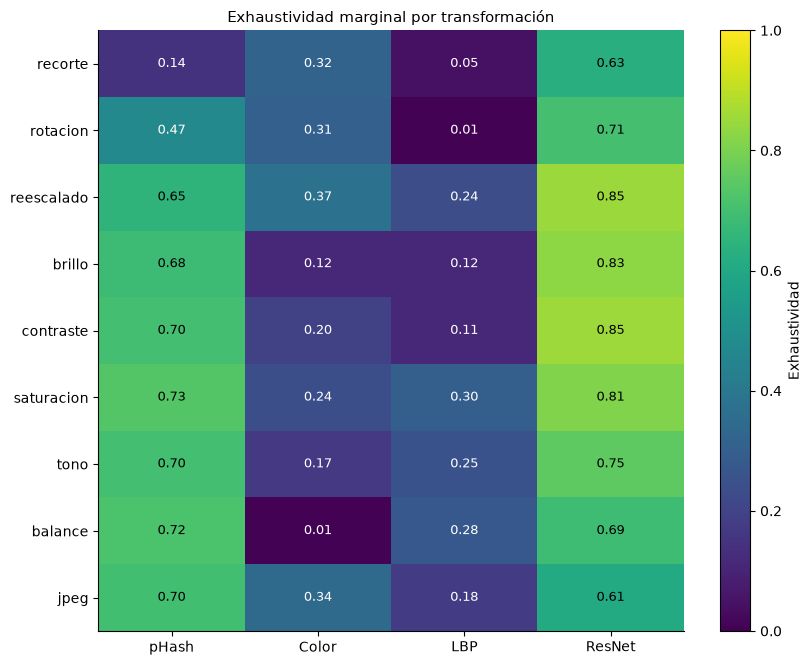

In [18]:
# [10. Por transformación] Mapa de calor de exhaustividad por transformación y representación.
t_ = tabla
fig, ax = plt.subplots(figsize=(1.5 * len(ORDEN) + 2.5, 0.55 * len(t_) + 1.8))
im = ax.imshow(t_.values, vmin=0, vmax=1, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(ORDEN))); ax.set_xticklabels(ORDEN)
ax.set_yticks(range(len(t_))); ax.set_yticklabels(t_.index); ax.grid(False)
for i in range(t_.shape[0]):
    for j in range(t_.shape[1]):
        v = t_.values[i, j]
        ax.text(j, i, "–" if np.isnan(v) else f"{v:.2f}", ha="center", va="center",
                color="white" if (np.isnan(v) or v < 0.6) else "black", fontsize=9)
ax.set_title("Exhaustividad marginal por transformación"); fig.colorbar(im, ax=ax, label="Exhaustividad")
plt.tight_layout(); plt.savefig(DIR_RES / "recall_transformacion.png", dpi=200); plt.show()

**Lectura.**
- **Tipo de par y acumulación.** Los pares variante–variante son más difíciles que original–variante (ResNet 0.551 frente a 0.748; pHash 0.415 frente a 0.610; color 0.065 frente a 0.230), y la exhaustividad cae al aumentar el número de transformaciones involucradas (ResNet 0.751 con 3 y 0.374 con 6; pHash 0.609 y 0.361; color y LBP ≈ 0.02 con 6). Un duplicado real rara vez acumula 6 transformaciones, así que es una cota pesimista.
- **pHash.** Buena ante color (0.68–0.73), JPEG (0.70) y reescalado (0.65); mala ante recorte (0.145) y media ante rotación (0.47).
- **Color.** Casi ciega al balance de color (0.006) y muy afectada por brillo (0.12), tono (0.17) y contraste (0.20), las transformaciones que se agregaron. Sus valores en rotación (0.31) y reescalado (0.37) no significan que sea frágil a ellas: cada variante lleva otras dos transformaciones, y ≈ 89 % de las variantes con rotación incluyen además alguna de color. El efecto aislado está en la sección 15.
- **ResNet.** La más pareja (0.61–0.85); lo más débil es JPEG (0.61) y recorte (0.63).
- **LBP.** Sus peores casos son rotación (0.006) y recorte (0.05).

Como cada variante lleva 3 transformaciones, esta tabla mezcla efectos: sirve para comparar el orden entre representaciones más que los valores absolutos.

## 11. Recuperación e incertidumbre

Visión de **búsqueda**: dada una imagen, se ordenan las demás por distancia y se mide qué tan arriba quedan sus duplicados.

- **mAP**: precisión promedio por consulta (sin umbral).
- **Top-1**: ¿el vecino más cercano es un duplicado?
- **R-precisión**: de los *R* duplicados reales de la consulta, cuántos aparecen entre los *R* más cercanos.

Los 5 folds son pocos para estimar la incertidumbre, así que se usa un **bootstrap por grupos** (se remuestrean grupos completos con reemplazo, porque las imágenes de un grupo no son independientes). Con los mismos remuestreos se obtienen diferencias pareadas entre representaciones.

In [19]:
# [11. Recuperación] Para cada imagen se ordenan las demás por distancia: AP, top-1 y R-precisión.
# Intervalos de confianza por bootstrap sobre grupos (N_BOOT remuestreos; el grupo es la unidad independiente).
def metricas_recuperacion(D, semilla=SEED):
    rng_r = np.random.default_rng(semilla)
    ap = np.full(n, np.nan); top1 = np.full(n, np.nan); rprec = np.full(n, np.nan)
    for q in range(n):
        mask = np.arange(n) != q
        d, rel = D[q, mask], (g[mask] == g[q])
        R = int(rel.sum())
        if R == 0:
            continue
        ap[q] = average_precision_score(rel, -d)
        orden = np.argsort(d + rng_r.random(d.shape) * 1e-9)       # desempate aleatorio
        top1[q] = rel[orden[0]]; rprec[q] = rel[orden[:R]].mean()
    return pd.DataFrame(dict(group_id=g, AP=ap, top1=top1, Rprec=rprec))

ret = {nm: metricas_recuperacion(D) for nm, D in matrices.items()}

def por_grupo(tabs, col):
    return pd.DataFrame({nm: t.groupby("group_id")[col].mean() for nm, t in tabs.items()})

def boot_medias(PG, B=N_BOOT, semilla=SEED):
    idx = np.random.default_rng(semilla).integers(0, len(PG), size=(B, len(PG)))
    V = PG.values
    return np.stack([V[idx, k].mean(1) for k in range(V.shape[1])], axis=1)     # B × representaciones

def resumen_boot(tabs):
    filas = {}
    for col, nombre in [("AP", "mAP"), ("top1", "Top-1"), ("Rprec", "R-precisión")]:
        PG = por_grupo(tabs, col); Bm = boot_medias(PG)
        lo, hi = np.percentile(Bm, [2.5, 97.5], axis=0)
        filas[nombre] = {nm: f"{PG[nm].mean():.3f} [{lo[k]:.3f}, {hi[k]:.3f}]" for k, nm in enumerate(PG.columns)}
    return pd.DataFrame(filas)

PG_AP = por_grupo(ret, "AP")
tab_ret = resumen_boot(ret).loc[ORDEN]
print(f"Referencia de azar (mAP) ≈ {PREVALENCIA:.3f} | IC 95 % bootstrap por grupos, {N_BOOT} remuestreos")
tab_ret

Referencia de azar (mAP) ≈ 0.008 | IC 95 % bootstrap por grupos, 2000 remuestreos


,mAP,Top-1,R-precisión
pHash,"0.568 [0.523, 0.613]","0.803 [0.772, 0.837]","0.542 [0.502, 0.586]"
Color,"0.175 [0.150, 0.202]","0.373 [0.325, 0.423]","0.162 [0.138, 0.188]"
LBP,"0.189 [0.160, 0.221]","0.355 [0.303, 0.410]","0.176 [0.148, 0.207]"
ResNet,"0.883 [0.852, 0.913]","0.968 [0.953, 0.983]","0.839 [0.802, 0.876]"


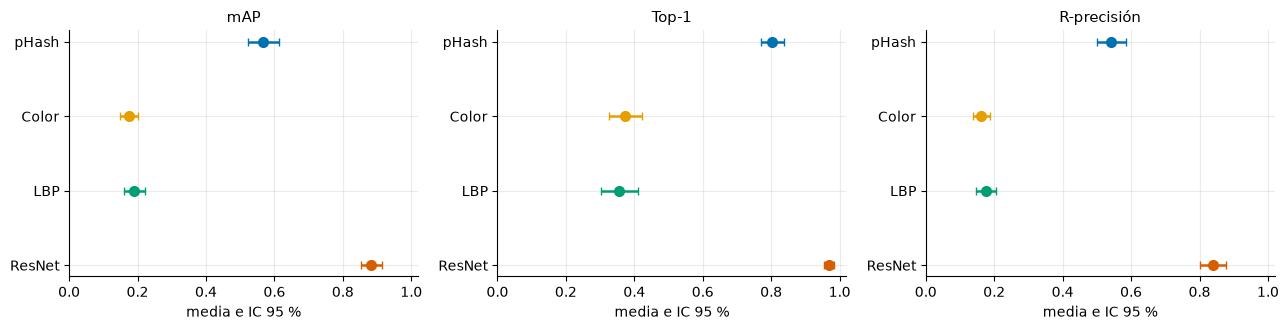

,delta_mAP,IC95_inf,IC95_sup,prob_mejor,distingue
comparacion,,,,,
ResNet − pHash,0.314,0.266,0.365,1.0,True
ResNet − Color,0.708,0.672,0.745,1.0,True
ResNet − LBP,0.694,0.657,0.731,1.0,True


In [20]:
# [11. Incertidumbre] Diferencias pareadas frente a la mejor representación, con los mismos remuestreos bootstrap.
# Diferencias pareadas (mismos remuestreos) respecto a la mejor representación por mAP
Bm = boot_medias(PG_AP)
mejor = PG_AP.mean().idxmax(); kb_ = list(PG_AP.columns).index(mejor)
filas = []
for k, nm in enumerate(PG_AP.columns):
    if nm == mejor:
        continue
    dlt = Bm[:, kb_] - Bm[:, k]
    lo, hi = np.percentile(dlt, [2.5, 97.5])
    filas.append(dict(comparacion=f"{mejor} − {nm}", delta_mAP=dlt.mean(), IC95_inf=lo, IC95_sup=hi,
                      prob_mejor=(dlt > 0).mean(), distingue=bool(lo > 0 or hi < 0)))
tab_delta = pd.DataFrame(filas).set_index("comparacion").round(3)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (col, nombre) in zip(axes, [("AP", "mAP"), ("top1", "Top-1"), ("Rprec", "R-precisión")]):
    PG = por_grupo(ret, col); B2 = boot_medias(PG); lo, hi = np.percentile(B2, [2.5, 97.5], axis=0)
    for k, nm in enumerate(PG.columns):
        m_ = PG[nm].mean()
        ax.errorbar(m_, k, xerr=[[m_ - lo[k]], [hi[k] - m_]], fmt="o", color=COLOR_REP.get(nm, "gray"),
                    capsize=3, ms=7, lw=1.8)
    ax.set_yticks(range(len(PG.columns))); ax.set_yticklabels(PG.columns); ax.invert_yaxis()
    ax.set_xlim(0, 1.02); ax.set_title(nombre); ax.set_xlabel("media e IC 95 %")
plt.tight_layout(); plt.savefig(DIR_RES / "recuperacion_ic.png", dpi=150); plt.show()
tab_delta

**Lectura.** En recuperación ResNet es claramente la mejor: su vecino más cercano es un duplicado en 96.8 % de las consultas (pHash 80.3 %, color 37.3 %, LBP 35.5 %) y recupera 83.9 % de los duplicados de una foto entre sus R vecinos más cercanos. Los intervalos bootstrap por grupos no se traslapan y las diferencias pareadas excluyen el cero con holgura (ResNet − pHash: +0.314 de mAP, IC 95 % [0.266, 0.365]; frente a color y LBP, ≈ +0.7). Color y LBP no se distinguen entre sí (intervalos de mAP [0.150, 0.202] y [0.160, 0.221]).

**Ranking relativo frente a umbral global.** El mAP por consulta de ResNet (0.883) es mucho mayor que su AP global (0.638, sección 9) y que su exhaustividad con un umbral único (0.617, sección 8). Para cada foto sus duplicados casi siempre quedan primero, pero la distancia a la que están varía de una foto a otra, y un corte global no sirve igual para todas. Un criterio relativo (por ejemplo, aceptar al vecino más cercano solo si es claramente más cercano que el segundo) podría aprovechar mejor esa ventaja; no se probó aquí.

## 12. Agrupamiento jerárquico aglomerativo

El corte del dendrograma se elige en entrenamiento (el que maximiza ARI) y se aplica a las imágenes del fold de prueba. Si el corte elegido queda pegado a un extremo del rango, amplía `Q_MIN` o `Q_MAX`.

In [21]:
# [12. Agrupamiento] Aglomerativo jerárquico; el corte del dendrograma se elige en entrenamiento maximizando el ARI.
# Se evalúa en el fold de prueba con ARI, homogeneidad, completitud y V-measure.
def evaluar_agrupamiento(D, nombre, metodo=None):
    metodo = metodo or LINKAGE
    D = preparar(D); filas = []
    for f in range(K):
        tr, te = np.where(fo != f)[0], np.where(fo == f)[0]
        d_tr = squareform(D[np.ix_(tr, tr)], checks=False)
        grid = np.unique(np.quantile(d_tr, np.geomspace(Q_MIN, Q_MAX, N_UMBRALES)))
        Z = linkage(d_tr, method=metodo)
        aris = [adjusted_rand_score(g[tr], fcluster(Z, t=u, criterion="distance")) for u in grid]
        u_best = grid[int(np.argmax(aris))]
        Zte = linkage(squareform(D[np.ix_(te, te)], checks=False), method=metodo)
        etiquetas = fcluster(Zte, t=u_best, criterion="distance")
        h, c, v = homogeneity_completeness_v_measure(g[te], etiquetas)
        filas.append(dict(representacion=nombre, fold=f, corte=u_best,
                          corte_en_borde=bool(u_best in (grid[0], grid[-1])),
                          ARI=adjusted_rand_score(g[te], etiquetas), homogeneidad=h, completitud=c, V=v,
                          n_grupos_pred=len(set(etiquetas)), n_grupos_real=len(set(g[te]))))
    return pd.DataFrame(filas)

res_clu = pd.concat([evaluar_agrupamiento(D, nm) for nm, D in matrices.items()])
print("Folds con el corte en el borde del rango:", int(res_clu.corte_en_borde.sum()), "de", len(res_clu))
(res_clu.groupby("representacion")[["ARI", "homogeneidad", "completitud", "V", "n_grupos_pred", "n_grupos_real"]]
        .agg(["mean", "std"]).loc[ORDEN].round(3))

Folds con el corte en el borde del rango: 0 de 20


ARI        homogeneidad        completitud             V  \
                 mean    std         mean    std        mean    std   mean   
representacion                                                               
pHash           0.687  0.074        0.979  0.018       0.827  0.026  0.897   
Color           0.172  0.046        0.928  0.040       0.658  0.010  0.769   
LBP             0.165  0.038        0.928  0.028       0.654  0.012  0.767   
ResNet          0.712  0.097        0.974  0.033       0.853  0.036  0.909   

                      n_grupos_pred         n_grupos_real       
                  std          mean     std          mean  std  
representacion                                                  
pHash           0.019          43.8   4.764          20.0  0.0  
Color           0.013          84.0  10.075          20.0  0.0  
LBP             0.014          82.6   7.092          20.0  0.0  
ResNet          0.025          39.4   7.470          20.0  0.0

**Lectura.** ResNet y pHash agrupan prácticamente igual de bien (ARI 0.712 ± 0.097 y 0.687 ± 0.074; V-measure 0.909 y 0.897): la diferencia es menor que la variación entre folds. Color y LBP quedan muy por debajo (ARI ≈ 0.17).

En todos los casos el error dominante es **fragmentar** y no mezclar: la homogeneidad es alta (0.93–0.98) pero la completitud no (0.65–0.85), y el número de grupos predicho es 39–44 con ResNet y pHash y ≈ 83 con color y LBP, frente a 20 reales por fold. Para unificar carpetas es el error más seguro: algunos duplicados quedan sin detectar, pero rara vez se fusionan fotos distintas. Ningún corte quedó en el borde del rango (0 de 20 folds), así que el rango de cuantiles fue adecuado.

## 13. Sensibilidad a hiperparámetros

¿Cuánto dependen los resultados de las decisiones de diseño? Se varían, de una en una, los hiperparámetros de las representaciones baratas y el método de enlace del agrupamiento. Para las representaciones se usa **AP global** (no depende de ningún umbral); para el enlace, el ARI medio entre folds. En ResNet-50 no se varía nada (se usa el vector de *avgpool* tal cual).

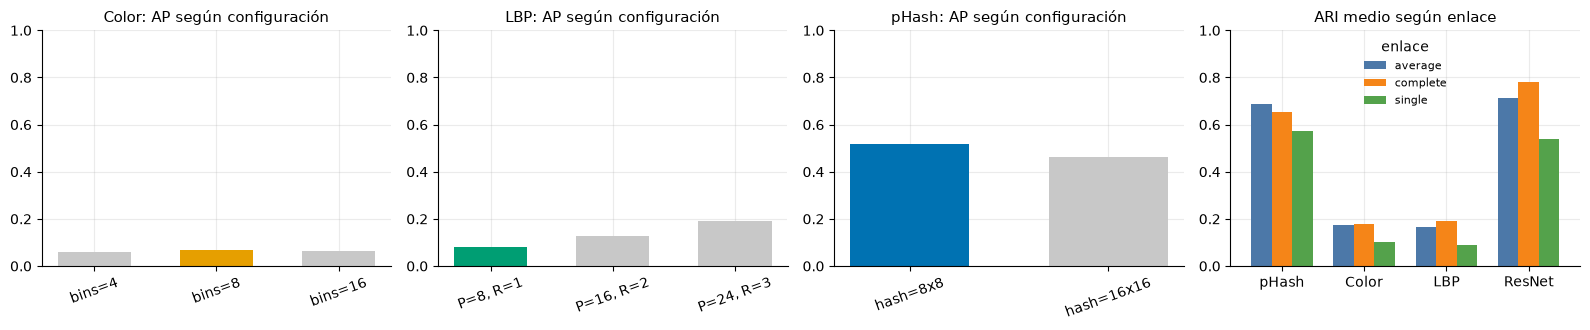

Configuración base resaltada en color; ResNet no se varía.
representacion configuracion    AP
         Color        bins=4 0.061
         Color        bins=8 0.066
         Color       bins=16 0.062
           LBP      P=8, R=1 0.080
           LBP     P=16, R=2 0.128
           LBP     P=24, R=3 0.191
         pHash      hash=8x8 0.517
         pHash    hash=16x16 0.464


enlace,average,complete,single
pHash,0.687,0.655,0.572
Color,0.172,0.178,0.102
LBP,0.165,0.191,0.088
ResNet,0.712,0.779,0.541


In [22]:
# [13. Sensibilidad] Efecto de hiperparámetros (bins de color, vecindario LBP, enlace) sobre el AP.
# Es descriptivo: no se usa para elegir la configuración reportada.
filas_s = []
if RUN_SENSIBILIDAD:
    def ap_de(X, fn): return average_precision_score(y_all, -fn(X)[I, J])
    for b in (4, 8, 16):
        filas_s.append(("Color", f"bins={b}", ap_de(extraer_desde_rutas(extraer_color, rutas, bins=b), dist_hellinger)))
    for (P_, R_) in ((8, 1), (16, 2), (24, 3)):
        filas_s.append(("LBP", f"P={P_}, R={R_}", ap_de(extraer_desde_rutas(extraer_lbp, rutas, P=P_, R=R_), dist_hellinger)))
    for hs in (8, 16):
        filas_s.append(("pHash", f"hash={hs}x{hs}", ap_de(extraer_desde_rutas(extraer_phash, rutas, hash_size=hs), dist_hamming)))
    sens = pd.DataFrame(filas_s, columns=["representacion", "configuracion", "AP"])
    sens["config_base"] = sens.configuracion.isin([f"bins={BINS_COLOR}", f"P={LBP_P}, R={LBP_R}", "hash=8x8"])

    enlaces = {}
    for m_ in ("average", "complete", "single"):
        enlaces[m_] = {nm: evaluar_agrupamiento(D, nm, metodo=m_).ARI.mean() for nm, D in matrices.items()}
    sens_enlace = pd.DataFrame(enlaces).loc[ORDEN].round(3)
    sens_enlace.columns.name = "enlace"

    reps_s = list(dict.fromkeys(sens.representacion))
    fig, axes = plt.subplots(1, len(reps_s) + 1, figsize=(4 * (len(reps_s) + 1), 3.4))
    for ax, nm in zip(axes, reps_s):
        s_ = sens[sens.representacion == nm]
        ax.bar(s_.configuracion, s_.AP, color=[COLOR_REP[nm] if b else "#C8C8C8" for b in s_.config_base], width=0.6)
        ax.set_title(f"{nm}: AP según configuración"); ax.set_ylim(0, 1); ax.tick_params(axis="x", labelrotation=20)
    sens_enlace.plot(kind="bar", ax=axes[-1], width=0.75, color=["#4C78A8", "#F58518", "#54A24B"])
    axes[-1].set_title("ARI medio según enlace"); axes[-1].set_ylim(0, 1); axes[-1].set_xlabel("")
    axes[-1].tick_params(axis="x", labelrotation=0); axes[-1].legend(title="enlace", fontsize=8)
    plt.tight_layout(); plt.savefig(DIR_RES / "sensibilidad.png", dpi=150); plt.show()
    print("Configuración base resaltada en color; ResNet no se varía.")
    print(sens.drop(columns="config_base").round(3).to_string(index=False))
sens_enlace if RUN_SENSIBILIDAD else "Sensibilidad desactivada (RUN_SENSIBILIDAD = False)"

**Lectura.** Las conclusiones no dependen de los hiperparámetros base:
- **Color.** El número de bins no importa (AP 0.061–0.066): el problema es la falta de invariancia al color, no la resolución del histograma.
- **LBP.** Mejora de forma monótona con vecindarios más grandes (AP 0.080 con P=8, R=1; 0.128 con P=16, R=2; 0.191 con P=24, R=3), así que la configuración base era la peor de las tres. Aun así queda muy por debajo de pHash (0.517).
- **pHash.** El hash de 8×8 (0.517) supera al de 16×16 (0.464): más bits no ayudan, probablemente porque el detalle fino es lo primero que rompen las transformaciones.
- **Enlace.** Con ResNet, *complete* da un ARI mayor (0.779) que *average* (0.712) y *single* es el peor (0.541); en pHash la mejor es *average* (0.687). Es una observación posterior a ver los datos: el enlace de la sección 12 se fijó antes, y elegir ahora *complete* sería optimista.

## 14. Fusión de representaciones

¿Combinar representaciones mejora? Cada matriz de distancias se divide entre su **mediana global** (no usa etiquetas, así que no hay fuga) y se promedian. Las combinaciones se fijan **de antemano** (no se busca la mejor entre todas) para no inflar el resultado por selección.

In [23]:
# [14. Fusión] Combina matrices de distancia normalizadas por su mediana global (sin usar etiquetas).
# Por qué: las distancias de cada representación tienen escalas distintas; la mediana las vuelve comparables.
mediana = {nm: np.median(D[I, J]) for nm, D in matrices.items()}
Dn = {nm: matrices[nm] / mediana[nm] for nm in matrices}
FUSIONES = {"Color+ResNet": ["Color", "ResNet"], "pHash+Color+ResNet": ["pHash", "Color", "ResNet"], "Todas": ORDEN}
FUSIONES = {k: v for k, v in FUSIONES.items() if all(c in matrices for c in v) and len(set(v)) > 1}
matrices_fus = {k: preparar(np.mean([Dn[c] for c in v], axis=0)) for k, v in FUSIONES.items()}

res_fus = pd.concat([evaluar(D, nm) for nm, D in matrices_fus.items()]) if matrices_fus else pd.DataFrame()
ret_fus = {nm: metricas_recuperacion(D) for nm, D in matrices_fus.items()}

def f1_medio(r):
    return (2 * r.precision * r.exhaustividad / (r.precision + r.exhaustividad + 1e-12)).mean()
filas = []
for nm in ORDEN + list(matrices_fus):
    D = matrices[nm] if nm in matrices else matrices_fus[nm]
    r = res[res.representacion == nm] if nm in matrices else res_fus[res_fus.representacion == nm]
    rt = ret[nm] if nm in ret else ret_fus[nm]
    filas.append(dict(representacion=nm, F1_pares=f1_medio(r), AP_global=average_precision_score(y_all, -D[I, J]),
                      mAP=rt.groupby("group_id").AP.mean().mean(), top1=rt.groupby("group_id").top1.mean().mean()))
tab_fus = pd.DataFrame(filas).set_index("representacion").round(3)

if matrices_fus:
    mejor_ind = tab_fus.loc[ORDEN].mAP.idxmax()
    PGf = por_grupo({**ret, **ret_fus}, "AP"); Bf = boot_medias(PGf); cols_f = list(PGf.columns)
    filas_d = []
    for nm in matrices_fus:
        dlt = Bf[:, cols_f.index(nm)] - Bf[:, cols_f.index(mejor_ind)]
        lo, hi = np.percentile(dlt, [2.5, 97.5])
        filas_d.append(dict(fusion=nm, vs=mejor_ind, delta_mAP=dlt.mean(), IC95_inf=lo, IC95_sup=hi, mejora_significativa=bool(lo > 0)))
    tab_delta_fus = pd.DataFrame(filas_d).set_index("fusion").round(3)
    print("Fusión frente a la mejor representación individual (por mAP):")
    print(tab_delta_fus.to_string())
tab_fus

Fusión frente a la mejor representación individual (por mAP):
                        vs  delta_mAP  IC95_inf  IC95_sup  mejora_significativa
fusion                                                                         
Color+ResNet        ResNet     -0.298    -0.337    -0.259                 False
pHash+Color+ResNet  ResNet     -0.128    -0.162    -0.094                 False
Todas               ResNet     -0.219    -0.254    -0.186                 False


,F1_pares,AP_global,mAP,top1
representacion,,,,
pHash,0.623,0.517,0.568,0.803
Color,0.185,0.066,0.175,0.373
LBP,0.166,0.080,0.189,0.355
ResNet,0.716,0.638,0.883,0.968
Color+ResNet,0.368,0.245,0.586,0.768
pHash+Color+ResNet,0.615,0.551,0.755,0.918
Todas,0.550,0.444,0.664,0.917


**Lectura.** La fusión **no** ayuda: las tres combinaciones quedan por debajo de ResNet solo, y no es un empate sino un empeoramiento (Δ mAP de −0.298 para Color+ResNet, −0.128 para pHash+Color+ResNet y −0.219 para Todas; los IC 95 % excluyen el cero). Con un promedio de pesos iguales, las representaciones débiles arrastran a la fuerte. La mejor combinación, pHash+Color+ResNet (mAP 0.755), sigue lejos de ResNet (0.883).

Esto rechaza la fusión por promedio simple, no la idea de fusionar en general: con pesos aprendidos, o con ResNet+pHash (que no se probó), el resultado podría ser distinto. El F1 de esta tabla es el promedio de F1 por fold y el de la sección 17 es el F1 de las medias; difieren en milésimas (0.716 frente a 0.719 en ResNet).

## 15. Prueba de estrés: una transformación a la vez

Complementa la sección 10 con un experimento **controlado**: se toman unos originales y se aplica **una sola** transformación con intensidad creciente (geométricas, de color y JPEG). Para cada representación se mide la fracción de originales cuya versión transformada sigue por debajo del **umbral operativo** (el de la sección 8), es decir, el porcentaje de duplicados que se detectaría.

Junto a cada curva se reporta la **tasa de falsos positivos** del mismo umbral (fracción de pares *no* duplicados que también quedarían por debajo). Un método que detecta todo a costa de aceptar muchos no duplicados no es útil.

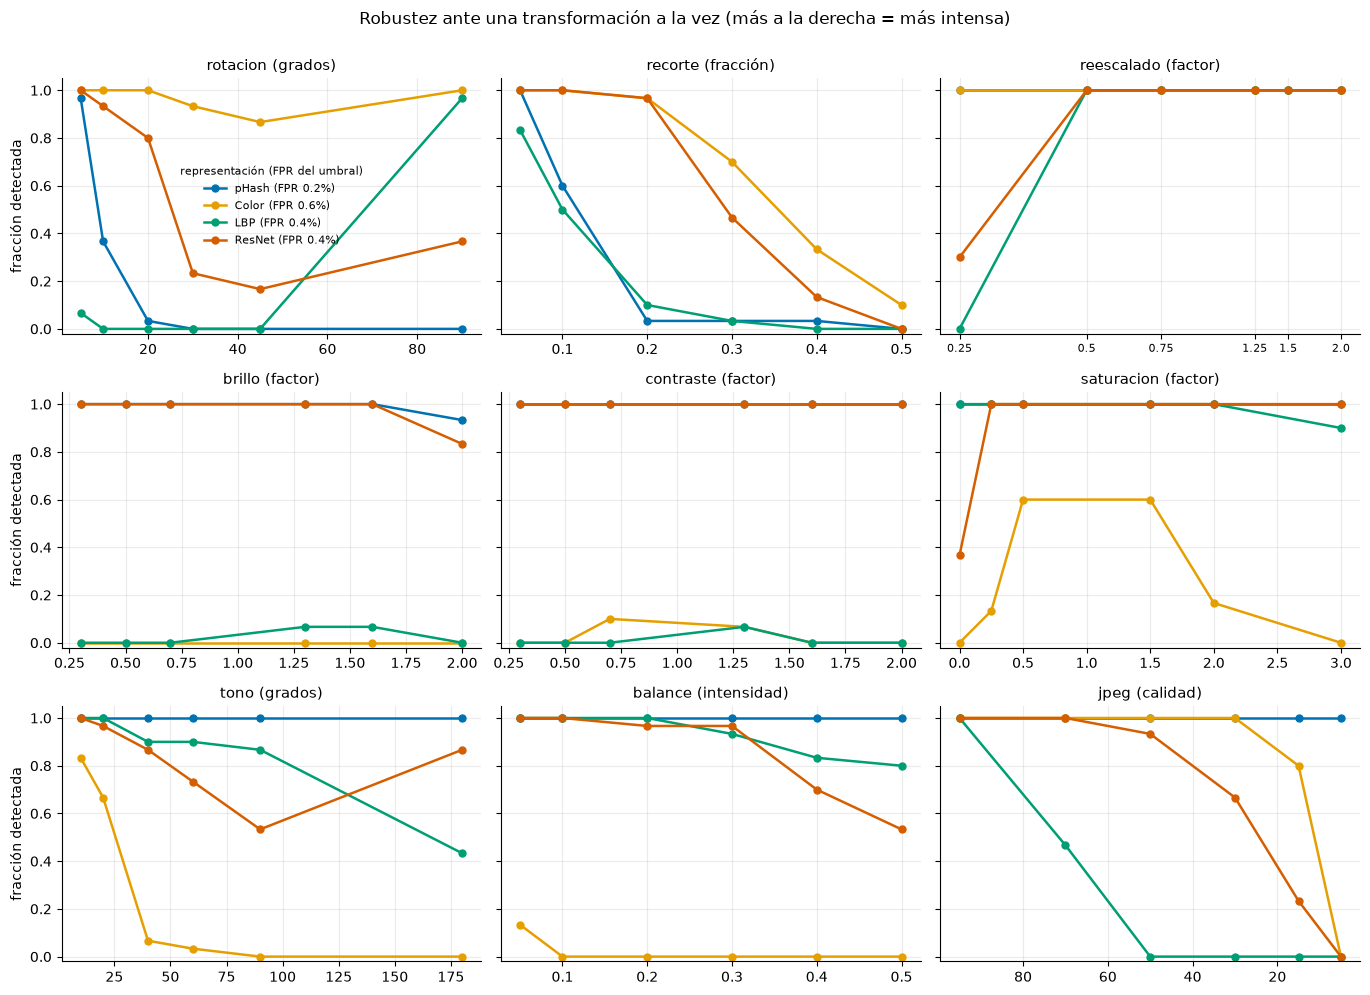

Nivel más intenso con detección ≥ 90 % (leído desde el nivel más suave):


,pHash,Color,LBP,ResNet
transformación,,,,
rotacion,5.00,30.0,ninguno,10.00
recorte,0.05,0.2,ninguno,0.20
reescalado,0.25,0.25,2.0,2.00
brillo,0.30,ninguno,ninguno,0.50
contraste,0.30,ninguno,ninguno,0.30
saturacion,0.00,ninguno,0.0,0.25
tono,180.00,ninguno,60.0,20.00
balance,0.50,ninguno,0.3,0.30
jpeg,5.00,30.0,95.0,50.00


In [24]:
# [15. Estrés] Una transformación a la vez con intensidad creciente (6 niveles), sobre imágenes nuevas (SEED + 2).
# Por qué: separar el efecto de cada transformación, que en el aumento principal aparecen combinadas.
def aplicar_nivel(op, img, nivel, rng):
    s = float(rng.choice([-1, 1]))
    if op == "rotacion":   return op_rotacion(img, nivel * s, color_borde(img))
    if op == "recorte":    return op_recorte(img, nivel, nivel, rng.random(), rng.random())
    if op == "reescalado": return op_reescalado(img, nivel)
    if op == "brillo":     return op_brillo(img, nivel)
    if op == "contraste":  return op_contraste(img, nivel)
    if op == "saturacion": return op_saturacion(img, nivel)
    if op == "tono":       return op_tono(img, nivel * s)
    if op == "balance":    return op_balance(img, 1 + nivel * s, 1 - nivel * s)
    if op == "jpeg":       return op_jpeg(img, nivel)
    raise ValueError(op)

# orden de dificultad creciente de los niveles (para reportar el límite de robustez)
DIFICULTAD = {"rotacion": lambda v: v, "recorte": lambda v: v, "tono": lambda v: v, "balance": lambda v: v,
              "reescalado": lambda v: abs(math.log2(v)), "brillo": lambda v: abs(math.log2(v)),
              "contraste": lambda v: abs(math.log2(v)), "saturacion": lambda v: abs(math.log2(max(v, 0.05))),
              "jpeg": lambda v: 100 - v}
UNIDAD = {"rotacion": "grados", "recorte": "fracción", "reescalado": "factor", "brillo": "factor", "contraste": "factor",
          "saturacion": "factor", "tono": "grados", "balance": "intensidad", "jpeg": "calidad"}

rob = pd.DataFrame()
if RUN_STRESS:
    rng_st = np.random.default_rng(SEED + 2)
    idx_orig = np.where(tipo == "original")[0]
    sel = rng_st.choice(idx_orig, size=min(STRESS["n_imagenes"], len(idx_orig)), replace=False)
    base_imgs = [cargar(rutas[i]) for i in sel]
    Xbase = {nm: EXTRACTORES[nm](base_imgs) for nm in ORDEN}
    filas = []
    for op, niveles in STRESS["niveles"].items():
        for nivel in niveles:
            imgs_t = [aplicar_nivel(op, im, nivel, rng_st) for im in base_imgs]
            for nm in ORDEN:
                dist = DIST_FILA[nm](Xbase[nm], EXTRACTORES[nm](imgs_t))
                filas.append(dict(operacion=op, nivel=nivel, representacion=nm,
                                  deteccion=float((dist <= UMBRAL_OP[nm]).mean()), dist_mediana=float(np.median(dist))))
            del imgs_t
    rob = pd.DataFrame(filas)
    rob.to_csv(DIR_RES / "robustez.csv", index=False)

    ops = list(STRESS["niveles"])
    ncol = 3; nfil = int(np.ceil(len(ops) / ncol))
    fig, axes = plt.subplots(nfil, ncol, figsize=(4.6 * ncol, 3.3 * nfil), sharey=True)
    for ax, op in zip(np.atleast_1d(axes).ravel(), ops):
        for nm in ORDEN:
            s_ = rob[(rob.operacion == op) & (rob.representacion == nm)].sort_values("nivel")
            ax.plot(s_.nivel, s_.deteccion, marker="o", ms=5, lw=1.8, color=COLOR_REP.get(nm, "gray"),
                    label=f"{nm} (FPR {fpr_op[nm]:.1%})")
        ax.set_title(f"{op} ({UNIDAD[op]})"); ax.set_ylim(-0.02, 1.05)
        if op == "jpeg": ax.invert_xaxis()
        if op == "reescalado": ax.set_xscale("log", base=2); ax.set_xticks(STRESS["niveles"][op]); ax.set_xticklabels([str(v) for v in STRESS["niveles"][op]], fontsize=8)
    for ax in np.atleast_1d(axes).ravel()[len(ops):]:
        ax.axis("off")
    for ax in np.atleast_1d(axes)[..., 0].ravel() if np.ndim(axes) > 1 else [np.atleast_1d(axes)[0]]:
        ax.set_ylabel("fracción detectada")
    np.atleast_1d(axes).ravel()[0].legend(fontsize=8, title="representación (FPR del umbral)", title_fontsize=8)
    plt.suptitle("Robustez ante una transformación a la vez (más a la derecha = más intensa)", y=1.0)
    plt.tight_layout(); plt.savefig(DIR_RES / "robustez.png", dpi=150, bbox_inches="tight"); plt.show()

    def limite(s_, op, umbral=0.9):
        s_ = s_.assign(dif=s_.nivel.apply(DIFICULTAD[op])).sort_values("dif")
        ultimo = None
        for _, r in s_.iterrows():
            if r.deteccion < umbral: break
            ultimo = r.nivel
        return "ninguno" if ultimo is None else ultimo
    limite_rob = pd.DataFrame({nm: {op: limite(rob[(rob.operacion == op) & (rob.representacion == nm)], op) for op in ops}
                               for nm in ORDEN})
    limite_rob.index.name = "transformación"
    print("Nivel más intenso con detección ≥ 90 % (leído desde el nivel más suave):")
limite_rob if RUN_STRESS else "Prueba de estrés desactivada (RUN_STRESS = False)"

**Lectura.** Detección al umbral operativo de cada método; tasa de falsos positivos de ese umbral: pHash 0.2 %, color 0.6 %, LBP 0.4 %, ResNet 0.4 %. Con 30 imágenes cada punto tiene una resolución de ≈ 3 puntos porcentuales. Los valores se leen de la figura; los exactos están en `resultados/robustez.csv`. El umbral viene de la calibración con variantes difíciles, así que probablemente es permisivo para una sola transformación.

Los perfiles son casi complementarios:
- **pHash** es prácticamente invariante a lo no geométrico: detecta ≈ 100 % con cualquier nivel de brillo, contraste, saturación, tono, balance y reescalado, e incluso con JPEG de calidad 5. Se rompe con la geometría: rotación (≈ 0.97 a 5°, ≈ 0.37 a 10°, ≈ 0 desde 20°) y recorte (≈ 0.6 con 10 %, ≈ 0.03 con 20 %).
- **Color** es lo opuesto: casi invariante a la rotación (≥ 0.87 hasta 90°), al reescalado (1.0 incluso a 0.25) y al JPEG hasta calidad 30. Detecta ≈ 0 con cambios de brillo o contraste desde el nivel más suave probado, ≈ 0.13 con balance de 0.05 y 0 desde 0.1, y cae a ≈ 0.07 con un tono de 40°.
- **ResNet** es el más equilibrado: ≈ 1.0 con brillo, contraste y reescalado ≥ 0.5; aguanta hasta 20 % de recorte (≈ 0.97) y 20° de rotación (≈ 0.8), y luego cae (≈ 0.47 con 30 % de recorte, ≈ 0.23 con 30°). Sufre con JPEG fuerte (≈ 0.67 a calidad 30, ≈ 0.23 a 15), con saturación 0 (≈ 0.37) y con balance o tono extremos (≈ 0.5).
- **LBP** solo detecta bien la rotación de 90° (≈ 0.97; es un giro exacto, sin interpolación, mientras que los demás ángulos interpolan y alteran la textura fina) y los cambios de saturación. Falla con brillo y contraste, algo inesperado porque en teoría es poco sensible a ellos; no se investigó la causa.

Ningún método cubre todo. pHash y color fallan en cosas opuestas (geometría frente a color), pero esa complementariedad no se tradujo en mejor desempeño con el promedio simple de la sección 14.

## 16. ¿Qué imágenes son difíciles?

Se relaciona la dificultad de cada grupo (AP medio de sus imágenes) con las propiedades del original medidas en la sección 2, mediante la correlación de Spearman. Es **exploratorio**: con varias propiedades y representaciones se hacen muchas pruebas, así que un valor-p pequeño aislado no es evidencia fuerte.

ρ de Spearman entre la propiedad del original y el AP de su grupo (valor-p en la tabla siguiente):
              pHash  Color   LBP  ResNet
brillo         0.06  -0.01  0.13   -0.13
contraste     -0.06  -0.22  0.09    0.03
saturacion     0.06  -0.07  0.16    0.39
entropia       0.04  -0.09  0.25    0.17
nitidez       -0.17  -0.16 -0.30   -0.29
bordes        -0.07  -0.05 -0.03   -0.15
colores_4bit  -0.15   0.04  0.02   -0.33
kb_src        -0.15  -0.08 -0.20   -0.07

valor-p:
              pHash  Color    LBP  ResNet
brillo        0.532  0.951  0.215   0.189
contraste     0.531  0.030  0.376   0.791
saturacion    0.584  0.505  0.110   0.000
entropia      0.670  0.382  0.014   0.100
nitidez       0.098  0.103  0.003   0.004
bordes        0.514  0.621  0.784   0.147
colores_4bit  0.127  0.660  0.880   0.001
kb_src        0.140  0.458  0.042   0.475


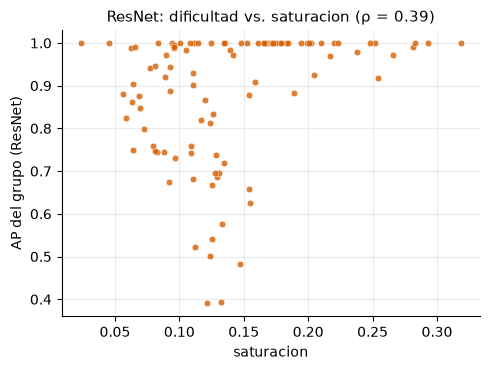

In [25]:
# [16. Dificultad] Relaciona el AP de cada grupo con las propiedades del original (correlación de Spearman).
# Solo descriptivo: no se usa para modelar.
pr = props.set_index("group_id")
comp = pd.concat([PG_AP.rename(columns=lambda c: f"AP_{c}"), pr], axis=1)
filas_r, filas_p = {}, {}
for nm in ORDEN:
    rr, pp = {}, {}
    for c in [c for c in COLS_PROP if comp[c].nunique() > 1]:
        r_, p_ = spearmanr(comp[c], comp[f"AP_{nm}"], nan_policy="omit")
        rr[c], pp[c] = r_, p_
    filas_r[nm], filas_p[nm] = rr, pp
rho = pd.DataFrame(filas_r).round(2); pval = pd.DataFrame(filas_p).round(3)
print("ρ de Spearman entre la propiedad del original y el AP de su grupo (valor-p en la tabla siguiente):")
print(rho.to_string()); print("\nvalor-p:"); print(pval.to_string())

mejor_rep = PG_AP.mean().idxmax()
prop_top = rho[mejor_rep].abs().idxmax()
fig, ax = plt.subplots(figsize=(5, 3.8))
ax.scatter(comp[prop_top], comp[f"AP_{mejor_rep}"], s=22, color=COLOR_REP.get(mejor_rep, "gray"), alpha=0.8, edgecolors="white", linewidths=0.4)
ax.set_xlabel(prop_top); ax.set_ylabel(f"AP del grupo ({mejor_rep})")
ax.set_title(f"{mejor_rep}: dificultad vs. {prop_top} (ρ = {rho.loc[prop_top, mejor_rep]:.2f})")
plt.tight_layout(); plt.savefig(DIR_RES / "dificultad.png", dpi=150); plt.show()

**Lectura.** La dificultad de un grupo se relaciona poco con las propiedades del original. Las únicas asociaciones claras son las de ResNet: con la saturación (ρ = +0.39, p < 0.001), con el número de colores distintos (ρ = −0.33, p = 0.001) y con la nitidez (ρ = −0.29, p = 0.004); es decir, fotos más saturadas, con menos colores y menos detalle fino se recuperan mejor. En LBP destacan la nitidez (ρ = −0.30) y la entropía (+0.25), y en pHash no hay ninguna con p < 0.05.

Son 32 pruebas: con una corrección de Bonferroni (α ≈ 0.0016) solo sobreviven las dos primeras de ResNet; el resto debe leerse como pista y no como evidencia. Incluso las más fuertes explican poca varianza (ρ² ≈ 0.15). Una explicación plausible, no probada, es que un objeto de color vivo destaca más sobre el fondo oscuro y que el detalle fino se pierde con el reescalado y el JPEG.

## 17. Tabla resumen y figuras

                    Precisión  Exhaustividad     F1            ARI   Homogeneidad    Completitud      V-measure     AP    mAP ms/imagen
representacion                                                                                                                         
pHash           0.904 ± 0.092   0.48 ± 0.053  0.627  0.687 ± 0.074  0.979 ± 0.018  0.827 ± 0.026  0.897 ± 0.019  0.517  0.568     0.994
Color           0.474 ± 0.166   0.12 ± 0.022  0.192  0.172 ± 0.046   0.928 ± 0.04   0.658 ± 0.01  0.769 ± 0.013  0.066  0.175     7.159
LBP             0.478 ± 0.134   0.103 ± 0.02  0.169  0.165 ± 0.038  0.928 ± 0.028  0.654 ± 0.012  0.767 ± 0.014   0.08  0.189     2.626
ResNet          0.863 ± 0.114  0.617 ± 0.028  0.719  0.712 ± 0.097  0.974 ± 0.033  0.853 ± 0.036  0.909 ± 0.025  0.638  0.883      3.69


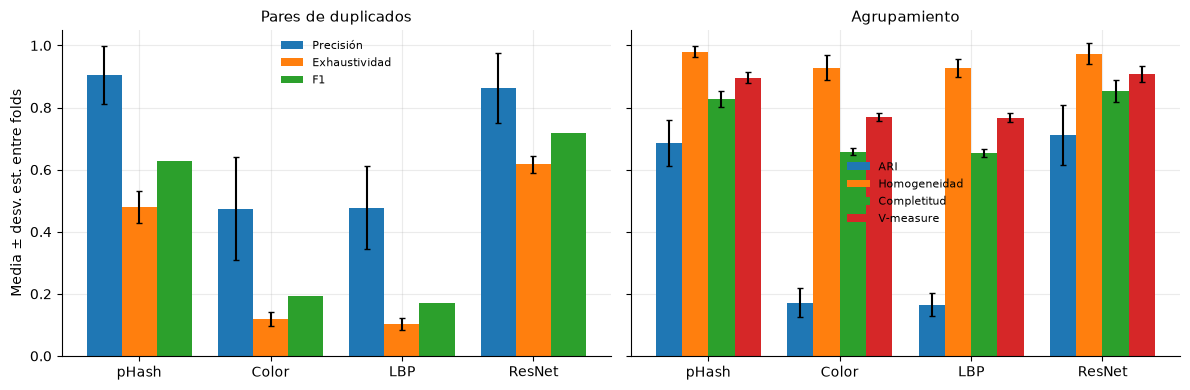

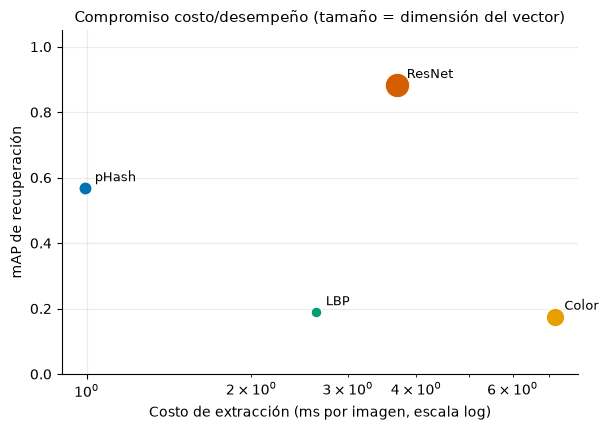

In [26]:
# [17. Resumen] Tabla comparativa de métricas, figuras de resumen y frente costo-desempeño.
cols = {"Precisión": (res, "precision"), "Exhaustividad": (res, "exhaustividad"),
        "ARI": (res_clu, "ARI"), "Homogeneidad": (res_clu, "homogeneidad"),
        "Completitud": (res_clu, "completitud"), "V-measure": (res_clu, "V")}
medias = pd.DataFrame({k: df.groupby("representacion")[c].mean() for k, (df, c) in cols.items()}).loc[ORDEN]
stds   = pd.DataFrame({k: df.groupby("representacion")[c].std()  for k, (df, c) in cols.items()}).loc[ORDEN]
medias.insert(2, "F1", 2*medias["Precisión"]*medias["Exhaustividad"]/(medias["Precisión"]+medias["Exhaustividad"]))
medias["AP"] = diag.loc[ORDEN, "AP"]
medias["mAP"] = PG_AP.mean()[ORDEN]
medias["ms/imagen"] = costo.ms_por_imagen[ORDEN]

resumen_txt = medias.round(3).astype(str)
for c in stds.columns:
    resumen_txt[c] = medias[c].round(3).astype(str) + " ± " + stds[c].round(3).astype(str)
resumen_txt.to_csv(DIR_RES / "resumen.csv"); tabla.to_csv(DIR_RES / "recall_transformacion.csv")
for nombre_, df_ in [("diagnostico", diag), ("costo", costo), ("recuperacion_ic", tab_ret), ("exhaustividad_precision_fija", tab_pf),
                     ("fusion", tab_fus), ("dif_pareadas", tab_delta), ("rho_dificultad", rho)]:
    df_.to_csv(DIR_RES / f"{nombre_}.csv")
print(resumen_txt.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, cs, titulo in [(axes[0], ["Precisión", "Exhaustividad", "F1"], "Pares de duplicados"),
                       (axes[1], ["ARI", "Homogeneidad", "Completitud", "V-measure"], "Agrupamiento")]:
    ancho, x = 0.8 / len(cs), np.arange(len(ORDEN))
    for k, c in enumerate(cs):
        err = stds[c].values if c in stds else None
        ax.bar(x + k*ancho, medias[c].values, ancho, yerr=err, capsize=2, label=c)
    ax.set_xticks(x + ancho*(len(cs)-1)/2); ax.set_xticklabels(ORDEN)
    ax.set_ylim(0, 1.05); ax.set_title(titulo); ax.legend(fontsize=8)
axes[0].set_ylabel("Media ± desv. est. entre folds")
plt.tight_layout(); plt.savefig(DIR_RES / "metricas.png", dpi=200); plt.show()

# Compromiso costo/desempeño
fig, ax = plt.subplots(figsize=(6.2, 4.4))
for nm in ORDEN:
    ax.scatter(costo.ms_por_imagen[nm], PG_AP[nm].mean(), s=40 + 6 * np.sqrt(costo.dimension[nm]),
               color=COLOR_REP.get(nm, "gray"), edgecolors="white", linewidths=0.8, zorder=3)
    ax.annotate(nm, (costo.ms_por_imagen[nm], PG_AP[nm].mean()), xytext=(7, 5), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("Costo de extracción (ms por imagen, escala log)"); ax.set_ylabel("mAP de recuperación")
ax.set_ylim(0, 1.05); ax.set_title("Compromiso costo/desempeño (tamaño = dimensión del vector)")
plt.tight_layout(); plt.savefig(DIR_RES / "costo_desempeno.png", dpi=200); plt.show()

**Lectura.** ResNet lidera en F1 (0.719), AP (0.638), mAP (0.883), ARI (0.712) y V-measure (0.909). pHash es segundo y casi iguala a ResNet en agrupamiento y en la precisión del punto de operación (0.904 frente a 0.863). En el plano costo/desempeño, **pHash y ResNet forman el frente de Pareto**: pHash es el más barato (1.0 ms/imagen) y ResNet el mejor (3.7 ms/imagen, en GPU). Color y LBP quedan dominados: cuestan más que pHash (7.6 y 2.7 ms) y rinden mucho menos (mAP 0.175 y 0.189 frente a 0.568). Recuerda la salvedad de hardware de la sección 6.

## 18. Análisis de errores

Se usa el umbral operativo de cada representación. Se muestran los **falsos negativos** más graves (duplicados con mayor distancia) y los **falsos positivos** más graves (no duplicados con menor distancia).

pHash: umbral=14.000 | FN=798 de 1500 duplicados | FP=277


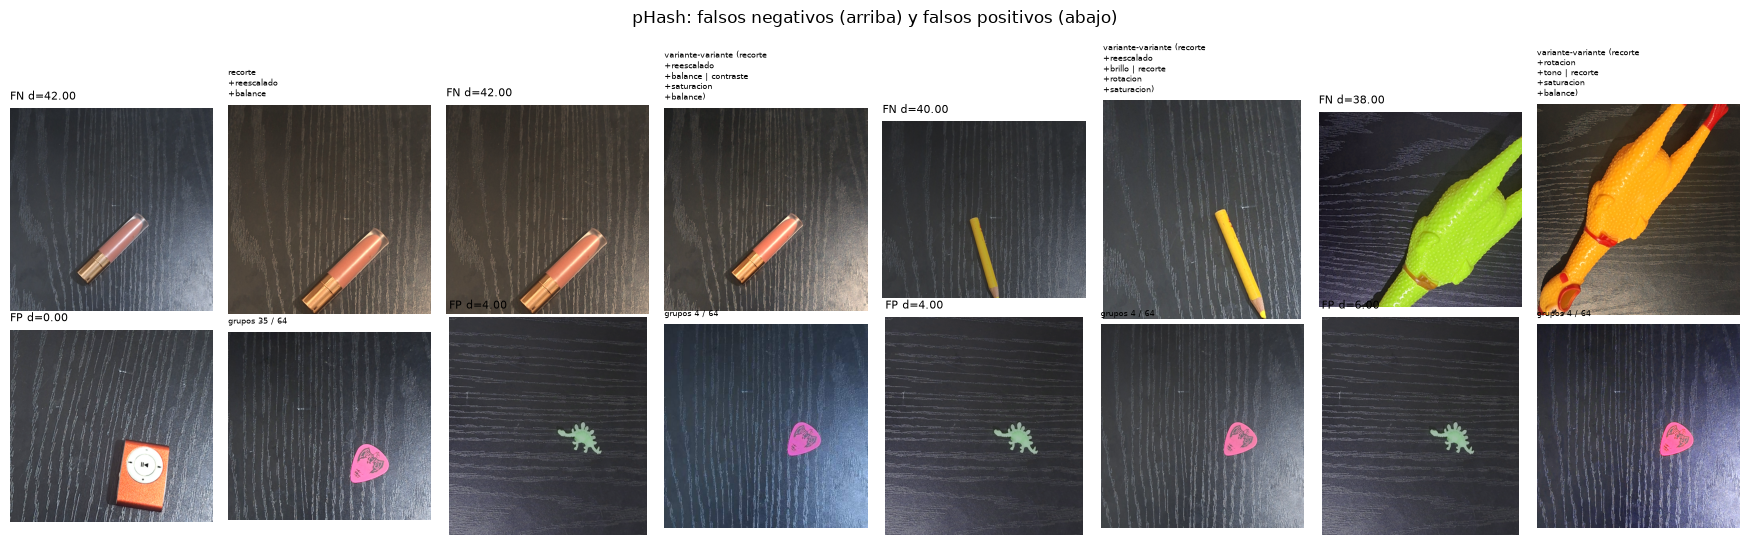

Color: umbral=0.273 | FN=1319 de 1500 duplicados | FP=1085


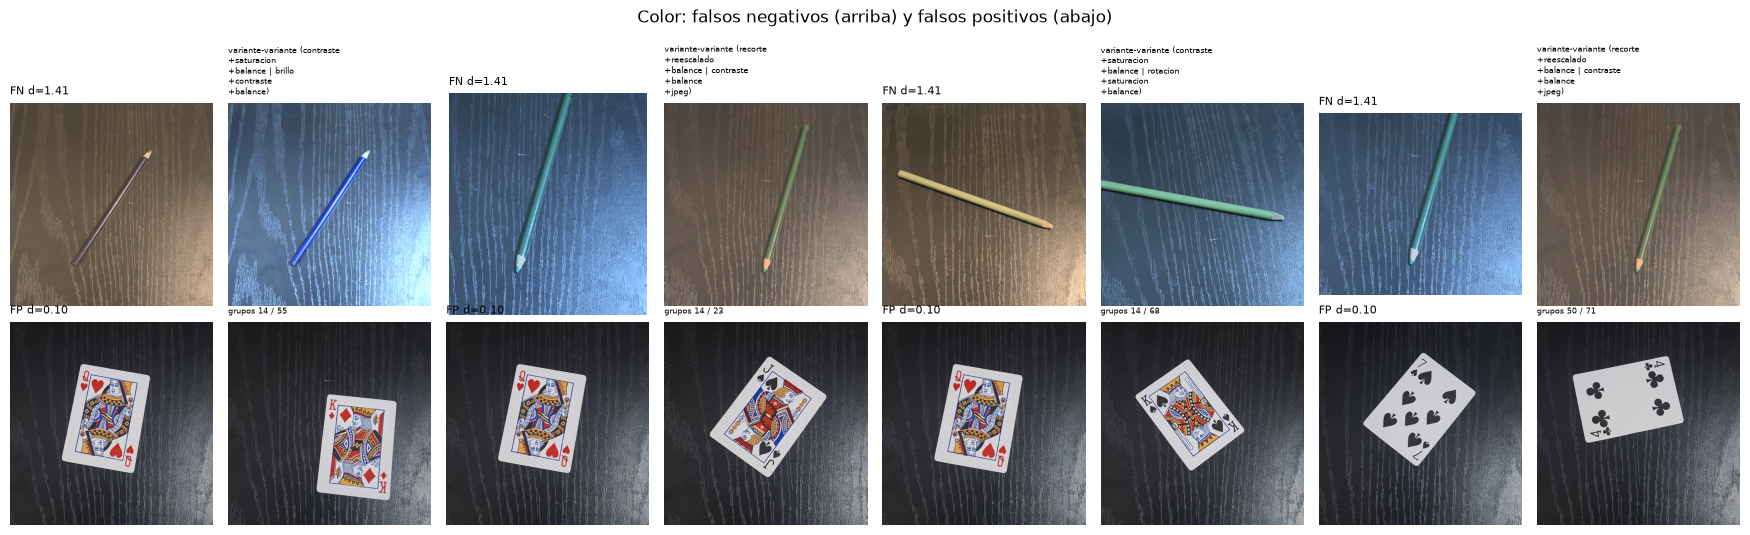

LBP: umbral=0.018 | FN=1346 de 1500 duplicados | FP=771


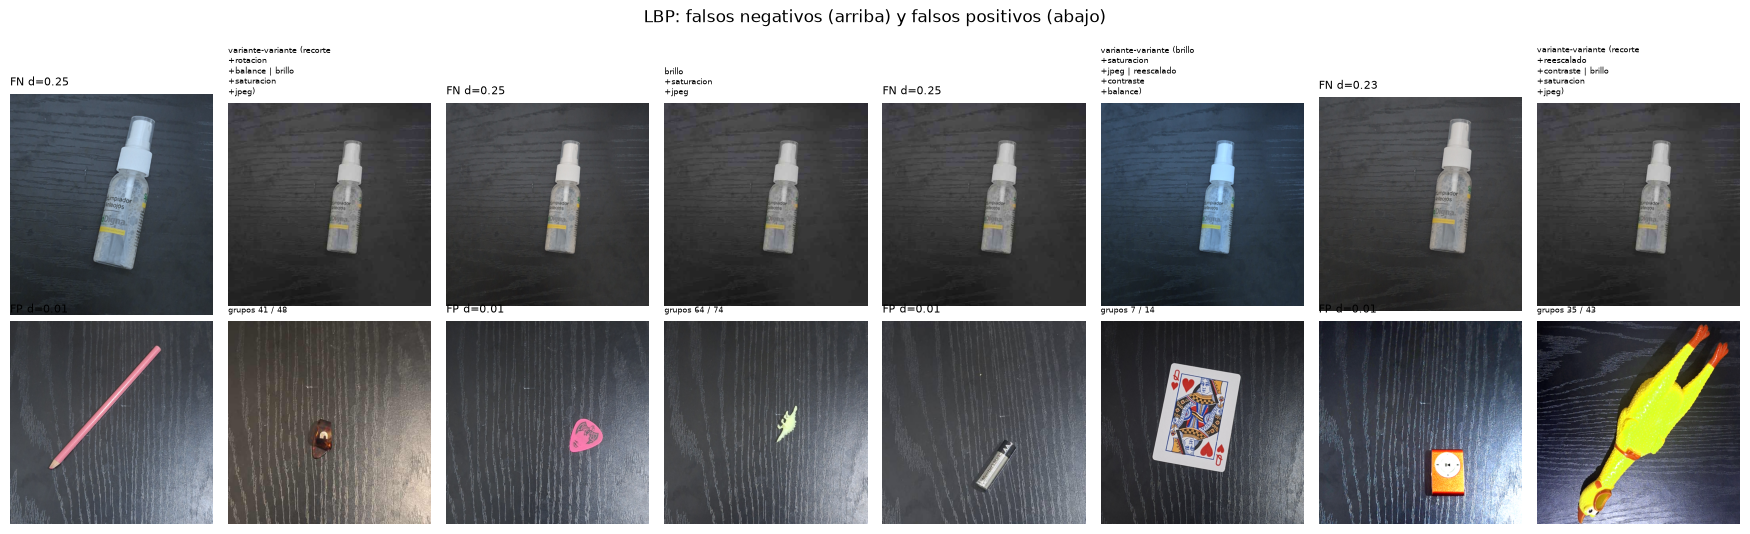

ResNet: umbral=0.157 | FN=563 de 1500 duplicados | FP=798


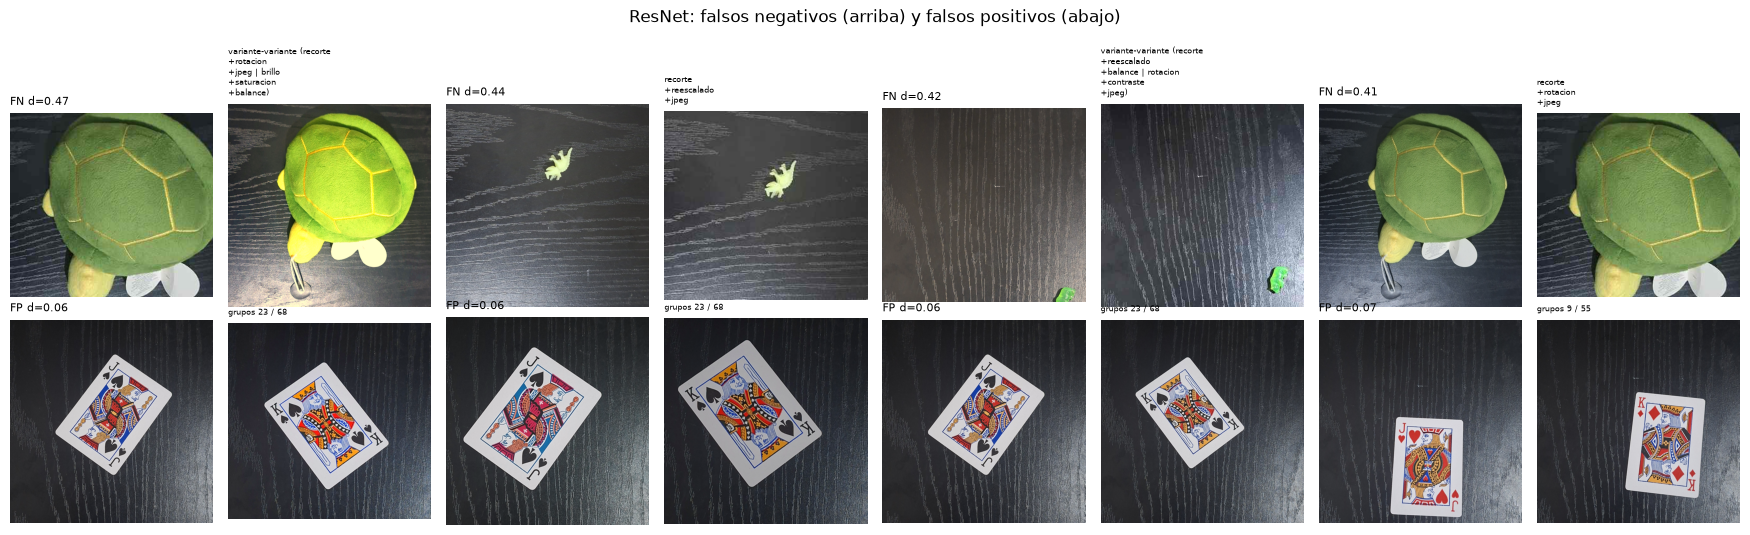

In [27]:
# [18. Errores] Falsos negativos y falsos positivos más extremos de cada representación, al umbral operativo.
# El umbral operativo es la mediana de los umbrales calibrados en los folds.
def mostrar_errores(nombre, k=4):
    D = matrices[nombre]; u = UMBRAL_OP[nombre]
    d = D[I, J]
    fn = np.where(y_all & (d > u))[0];   fn = fn[np.argsort(-d[fn])][:k]
    fp = np.where(~y_all & (d <= u))[0]; fp = fp[np.argsort(d[fp])][:k]
    print(f"{nombre}: umbral={u:.3f} | FN={int((y_all & (d > u)).sum())} de {int(y_all.sum())} duplicados "
          f"| FP={int((~y_all & (d <= u)).sum())}")
    fig, axes = plt.subplots(2, 2*k, figsize=(2.2*2*k, 5.4))
    for fila, (idxs, nom) in enumerate([(fn, "FN"), (fp, "FP")]):
        for c in range(k):
            a1, a2 = axes[fila, 2*c], axes[fila, 2*c + 1]
            a1.axis("off"); a2.axis("off")
            if c < len(idxs):
                p = idxs[c]; i, j = I[p], J[p]
                a1.imshow(cargar(rutas[i])); a2.imshow(cargar(rutas[j]))
                extra = etiqueta_par(i, j).replace("+", "\n+") if nom == "FN" else f"grupos {g[i]} / {g[j]}"
                a1.set_title(f"{nom} d={d[p]:.2f}", fontsize=8, loc="left")
                a2.set_title(extra, fontsize=6, loc="left")
    fig.suptitle(f"{nombre}: falsos negativos (arriba) y falsos positivos (abajo)", y=1.0)
    plt.tight_layout(); plt.savefig(DIR_RES / f"errores_{nombre}.png", dpi=150); plt.show()

for nm in ORDEN:
    mostrar_errores(nm)

**Lectura.** Se muestran los 4 casos más extremos de cada tipo, no una muestra representativa.
- **ResNet, falsos positivos (d ≈ 0.06–0.07).** Pares de naipes distintos (J contra K), rotados: el embedding reconoce «naipe» y la distancia es tan baja como la de un duplicado real. Es el error típico de un modelo semántico con objetos del mismo tipo.
- **ResNet, falsos negativos (d ≈ 0.41–0.47).** El peluche verde con varias transformaciones de color y geometría acumuladas, y fotos casi vacías donde el objeto es diminuto y el recorte deja casi solo la madera: el duplicado es difícil de reconocer incluso para una persona. Esto sugiere que parte de la exhaustividad perdida viene de cómo se construye la verdad de referencia y no del método.
- **pHash, falsos positivos (d = 0–6).** Fotos distintas con un objeto pequeño (un aparato naranja, una púa rosa, un dinosaurio de juguete) sobre la misma madera: el hash de bajas frecuencias queda dominado por el fondo, idéntico en todas.
- **pHash, falsos negativos (d ≈ 38–42).** Objetos con varias transformaciones combinadas (recorte, reescalado, balance de color, rotación); la composición cambia tanto que el hash ya no se parece.

Los paneles de color y LBP no se comentan por ser los de peor desempeño.

## 19. Conclusiones

La primera celda resume los resultados **a partir de los números calculados** (se actualiza sola al volver a correr). Después se listan limitaciones que no dependen de los números.

In [28]:
# [19. Conclusiones] Texto generado a partir de los números calculados arriba, para que no se desactualice.
L = []
mejor_f1 = medias.F1.idxmax(); mejor_map = medias.mAP.idxmax()
L.append(f"- **Pares (umbral calibrado):** mejor F1 = **{mejor_f1}** ({medias.F1[mejor_f1]:.3f}); azar ≈ {PREVALENCIA:.3f}. "
         f"**Recuperación:** mejor mAP = **{mejor_map}** ({medias.mAP[mejor_map]:.3f}).")
if len(tab_delta):
    cerca = tab_delta[~tab_delta.distingue.astype(bool)].index.tolist()
    L.append("- **Incertidumbre:** " + (f"no se distingue a {mejor_map} de " + ", ".join(c.split(' − ')[1] for c in cerca) + " (el IC 95 % de la diferencia incluye 0)."
             if cerca else f"{mejor_map} supera a todas las demás con IC 95 % de la diferencia por encima de 0."))
for pm in P_MIN:
    s_ = res_pf[res_pf.p_min == pm].groupby("representacion").exhaustividad.mean()
    L.append(f"- **Con precisión ≥ {pm:.0%}:** mejor exhaustividad = **{s_.idxmax()}** ({s_.max():.3f}).")
debil = {nm: (tabla[nm].idxmin(), tabla[nm].min()) for nm in ORDEN if tabla[nm].notna().any()}
L.append("- **Transformación más dañina (exhaustividad marginal):** " + "; ".join(f"{nm}: {t} ({v:.2f})" for nm, (t, v) in debil.items()) + ".")
if RUN_STRESS and len(limite_rob):
    for nm in ORDEN:
        sin = [op for op in limite_rob.index if limite_rob.loc[op, nm] == "ninguno"]
        L.append(f"- **Estrés, {nm}:** no tolera ni el nivel más suave de " + (", ".join(sin) if sin else "(ninguna transformación)") + ".")
barato = costo.ms_por_imagen.idxmin()
L.append(f"- **Costo:** {barato} es la más barata ({costo.ms_por_imagen[barato]:.2f} ms/imagen); {mejor_map} cuesta "
         f"{costo.ms_por_imagen[mejor_map] / costo.ms_por_imagen[barato]:.0f}× más por imagen.")
if matrices_fus:
    fus = tab_delta_fus
    L.append("- **Fusión:** " + "; ".join(f"{k}: Δ mAP = {r.delta_mAP:+.3f} vs. {r.vs} ({'mejora significativa' if r.mejora_significativa else 'sin mejora significativa'})" for k, r in fus.iterrows()) + ".")
L.append("- **Hipótesis:** contrasta H1–H6 de la sección 0 con estos números; si alguna no se cumple, dilo, es un resultado.")
mostrar_md("\n".join(L))

- **Pares (umbral calibrado):** mejor F1 = **ResNet** (0.719); azar ≈ 0.008. **Recuperación:** mejor mAP = **ResNet** (0.883).
- **Incertidumbre:** ResNet supera a todas las demás con IC 95 % de la diferencia por encima de 0.
- **Con precisión ≥ 95%:** mejor exhaustividad = **pHash** (0.333).
- **Con precisión ≥ 99%:** mejor exhaustividad = **pHash** (0.230).
- **Transformación más dañina (exhaustividad marginal):** pHash: recorte (0.14); Color: balance (0.01); LBP: rotacion (0.01); ResNet: jpeg (0.61).
- **Estrés, pHash:** no tolera ni el nivel más suave de (ninguna transformación).
- **Estrés, Color:** no tolera ni el nivel más suave de brillo, contraste, saturacion, tono, balance.
- **Estrés, LBP:** no tolera ni el nivel más suave de rotacion, recorte, brillo, contraste.
- **Estrés, ResNet:** no tolera ni el nivel más suave de (ninguna transformación).
- **Costo:** pHash es la más barata (0.99 ms/imagen); ResNet cuesta 4× más por imagen.
- **Fusión:** Color+ResNet: Δ mAP = -0.298 vs. ResNet (sin mejora significativa); pHash+Color+ResNet: Δ mAP = -0.128 vs. ResNet (sin mejora significativa); Todas: Δ mAP = -0.219 vs. ResNet (sin mejora significativa).
- **Hipótesis:** contrasta H1–H6 de la sección 0 con estos números; si alguna no se cumple, dilo, es un resultado.

### Conclusiones

**Respuesta a la pregunta.** Para detectar y agrupar duplicados en esta colección, ResNet-50 es la mejor representación (mAP 0.883, top-1 96.8 %, F1 de pares 0.719, ARI 0.712), pero no gana en todo: en agrupamiento empata con pHash (ARI 0.687) y con precisión ≥ 95 % pHash conserva más duplicados (exhaustividad 0.333 frente a 0.209). Color y LBP no son competitivos aquí (mAP 0.175 y 0.189). El costo no explica la diferencia: pHash es la más barata y ResNet la mejor, mientras que color y LBP cuestan más que pHash y rinden menos.

**Veredicto de las hipótesis de la sección 0**

| | Veredicto | Evidencia |
|---|---|---|
| H1 | Parcial | ResNet gana en ranking (ΔmAP +0.314 frente a pHash, IC 95 % [0.266, 0.365]) y en F1 (0.719 frente a 0.627). En agrupamiento no se distingue de pHash (ARI 0.712 ± 0.097 frente a 0.687 ± 0.074) y con precisión ≥ 95 % pierde frente a pHash. |
| H2 | Se cumple | pHash: JPEG 0.70, reescalado 0.65 (y ≈ 1.0 en estrés incluso con calidad 5 y escala 0.25); recorte 0.145, rotación 0.47. Además es robusto a las transformaciones de color (0.68–0.73). |
| H3 | Se cumple | Color: invariante a rotación y reescalado en estrés (≥ 0.87 y 1.0), pero ≈ 0 con brillo, contraste y balance (exhaustividad marginal con balance 0.006); AUC 0.674, también por el fondo común de las fotos. |
| H4 | A medias | LBP es de las más débiles, pero empata con color (mAP 0.189 frente a 0.175 con intervalos traslapados; ARI 0.165 frente a 0.172). Mejora con vecindarios mayores (AP 0.080 → 0.191). |
| H5 | No se cumple (con promedio simple) | Las tres fusiones empeoran respecto a ResNet (ΔmAP de −0.298 a −0.128, IC 95 % bajo cero). |
| H6 | Se cumple con matiz | El frente de Pareto es pHash + ResNet; color y LBP quedan dominados. ResNet cuesta 3.6 veces más por imagen (en GPU), unas 33 veces más por comparación y 1,024 veces más en almacenamiento. |

**Lectura práctica** (a validar con duplicados reales): pHash sirve como filtro barato y de alta precisión cuando los duplicados difieren en color, compresión o tamaño; ResNet es preferible cuando pueden haber rotación o recorte y se puede pagar su costo; color y LBP no se recomiendan solos. Conviene un criterio de aceptación relativo (vecino más cercano frente al segundo) en lugar de un único umbral global, que es donde ResNet pierde más.

**Cómo leer la celda anterior.** (a) En las líneas «Estrés», «no tolera ni el nivel más suave de (ninguna transformación)» significa que ninguna falla en el nivel más suave. (b) En «Fusión», «sin mejora significativa» es en realidad *significativamente peor* (ver sección 14).

**Contexto con la corrida anterior.** En la corrida anterior de este proyecto (sin transformaciones de color y con relleno negro en las rotaciones) el F1 de pares fue 0.508 para color, 0.249 para pHash y 0.635 para ResNet; ahora es 0.192, 0.627 y 0.719. No se puede atribuir cada cambio a una sola causa porque se modificaron dos cosas a la vez: la mejora de pHash coincide con quitar el relleno negro y la caída de color con agregar transformaciones de color.

**Limitaciones y amenazas a la validez**

- **Duplicados sintéticos.** La verdad de referencia sale de transformaciones controladas; los duplicados reales (capturas de pantalla, re-exportaciones de apps, ráfagas del teléfono, ediciones manuales) pueden comportarse distinto.
- **Una sola colección y pocos originales.** Los resultados dependen del contenido de las fotos y de su variedad; no se generalizan sin más a otras colecciones. Los intervalos bootstrap cuantifican el muestreo de grupos, no el cambio de colección.
- **Prevalencia artificial.** La proporción de duplicados en el experimento (muy baja entre todos los pares) puede diferir de la de una colección real, y la precisión depende de ella.
- **Umbrales calibrados dentro del mismo diseño.** El umbral se ajusta con folds del mismo experimento; en otra colección hay que recalibrarlo.
- **Transformaciones combinadas.** Con varias por variante, el efecto de cada una se mezcla (sección 10); la prueba de estrés los separa, pero a un solo nivel por vez y sobre pocos originales.
- **Selección de hiperparámetros.** Los hiperparámetros base se fijaron a priori; la sensibilidad (sección 13) muestra cuánto importan, pero no es una búsqueda exhaustiva.
- **Costo medido en una máquina.** Los milisegundos dependen del hardware (CPU/GPU); es válido el orden relativo, no el valor absoluto.
- **Trabajo futuro:** duplicados reales etiquetados a mano, más tipos de transformación (ruido, desenfoque, marcas de agua, espejo), embeddings de otros modelos y búsqueda aproximada de vecinos para colecciones grandes.

**Limitaciones observadas en esta corrida**

- **Colección única y homogénea.** Son 100 fotos de objetos sobre la misma mesa. El fondo común favorece o perjudica a cada método de forma específica (por ejemplo, pHash confunde fotos con un objeto pequeño) y los resultados no se generalizan a colecciones variadas (paisajes, personas, interiores).
- **Pocos grupos.** Con 20 grupos por fold, las métricas por fold son ruidosas. Los intervalos bootstrap miden el muestreo de grupos de esta colección, no el cambio de colección.
- **Positivos muy exigentes.** Cada variante lleva 3 transformaciones y los pares entre variantes acumulan hasta 6. Algunos positivos son casi irreconocibles (el recorte deja solo el fondo), así que las exhaustividades son cotas pesimistas para duplicados reales.
- **Costo con hardware mixto.** ResNet se midió en GPU y el resto en CPU.
- **Umbral global calibrado en esta colección.** En otra hay que recalibrarlo, y el desempeño de ResNet depende mucho de esa elección.
- **Hallazgos exploratorios.** La sección 16 y las explicaciones propuestas en las secciones 15 y 18 son hipótesis; el enlace *complete* y la configuración de LBP se observaron después de ver los datos.

## Respuesta a las preguntas de investigación

- **P1. ¿Qué representación detecta mejor?** ResNet-50: mejor F1 de pares (0.719), AP (0.638) y mAP (0.883). Con precisión ≥ 95 % pHash conserva más duplicados (0.333 frente a 0.209). Color y LBP no son competitivos (mAP 0.175 y 0.189).
- **P2. ¿ResNet supera a pHash y a qué costo?** Sí en ranking (ΔmAP +0.314, IC 95 % [0.266, 0.365]) y en F1 (0.719 frente a 0.627). En agrupamiento no se distinguen (ARI 0.712 y 0.687). Cuesta unas 33 veces más por comparación y 1,024 veces más en almacenamiento.
- **P3. ¿Qué transformaciones rompen a cada una?** pHash: recorte y rotación; color: brillo, contraste y balance; ResNet: JPEG fuerte, rotaciones de más de 20° y recortes de más de 20 %.
- **P4. ¿Agrupa bien y ayuda fusionar?** El agrupamiento jerárquico alcanza ARI 0.712 con ResNet y 0.687 con pHash. Fusionar con promedio simple empeora (ΔmAP de −0.298 a −0.128).

Las cifras vienen de las secciones 8–15 y 17 de la corrida con huella `b8b53792e2`; la evidencia completa y las limitaciones están en la sección 19.

## 20. Reproducibilidad

**Reproducibilidad de esta corrida**

- **Semillas fijas:** `SEED = 42` (general), `SEED + 1` (variantes), `SEED + 2` (estrés), `SEED + 3` (costo); se guardan en `resultados/run_info.json`.
- **Rutas relativas** a la carpeta del notebook (`RAIZ = Path(".")`).
- **Versiones** de librerías: se imprimen en la celda siguiente y se guardan en `requirements-lock.txt`; `requirements.txt` da versiones mínimas.
- **Caché con huella:** si cambian los datos o los parámetros, se recalcula en lugar de reutilizar vectores viejos.
- **No determinismo residual:** ResNet-50 en GPU puede variar en las últimas cifras decimales entre equipos.

In [29]:
# [20. Reproducibilidad] Versiones de las librerías, semillas y configuración de la corrida (resultados/run_info.json).
# Además imprime las versiones y escribe requirements-lock.txt (versiones exactas) para recrear el entorno.
from importlib import metadata
def version(p):
    try: return metadata.version(p)
    except Exception: return "no instalado"
VERSIONES = {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "scikit-image", "pillow",
                                     "imagehash", "matplotlib", "torch", "torchvision"]}
info_ejecucion = dict(
    fecha=time.strftime("%Y-%m-%d %H:%M:%S"), python=sys.version.split()[0], plataforma=platform.platform(),
    dispositivo_resnet=_RESNET.get("dev", "no usado"), versiones=VERSIONES,
    semillas=dict(general=SEED, variantes=SEED + 1, estres=SEED + 2, costo=SEED + 3),
    modo=MODO, n_originales=int(len(originales)), n_imagenes=int(n), n_pares=int(len(pares)), n_positivos=int(y_all.sum()),
    huella_datos=HUELLA, rotacion_borde=ROT_BORDE, filtrado=FILTRADO,
    config={k: v for k, v in CONFIG.items()}, K=K, linkage=LINKAGE, bins_color=BINS_COLOR, lbp=[LBP_P, LBP_R, LBP_LADO],
    n_boot=N_BOOT, stress=STRESS, tiempo_total_s=round(time.time() - T0, 1))
with open(DIR_RES / "run_info.json", "w", encoding="utf-8") as f:
    json.dump(info_ejecucion, f, indent=2, ensure_ascii=False, default=str)
print(f"Tiempo total: {info_ejecucion['tiempo_total_s']} s | huella de datos: {HUELLA}")
print("Guardado en resultados/run_info.json (configuración, semillas y versiones). Archivos generados:")
print(sorted(p.name for p in DIR_RES.iterdir()))

# --- Versiones declaradas: se imprimen y se guardan como requirements-lock.txt ---
print("Versiones:", VERSIONES)
print("Python:", sys.version.split()[0], "| semilla:", SEED)
with open(RAIZ / "requirements-lock.txt", "w", encoding="utf-8") as f_lock:
    for _p, _v in VERSIONES.items():
        if _v != "no instalado":
            f_lock.write(f"{_p}=={_v}\n")

Tiempo total: 165.7 s | huella de datos: b8b53792e2
Guardado en resultados/run_info.json (configuración, semillas y versiones). Archivos generados:
['costo.csv', 'costo_desempeno.png', 'curvas_pr.png', 'diagnostico.csv', 'dif_pareadas.csv', 'dificultad.png', 'distribuciones_distancia.png', 'eda_correlacion.png', 'eda_originales.png', 'eda_variantes.png', 'errores_Color.png', 'errores_LBP.png', 'errores_ResNet.png', 'errores_pHash.png', 'exhaustividad_precision_fija.csv', 'fusion.csv', 'metricas.png', 'recall_transformacion.csv', 'recall_transformacion.png', 'recuperacion_ic.csv', 'recuperacion_ic.png', 'resumen.csv', 'rho_dificultad.csv', 'robustez.csv', 'robustez.png', 'run_info.json', 'sensibilidad.png', 'tsne.png']
Versiones: {'numpy': '2.5.5', 'pandas': '3.1.1', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'scikit-image': '0.26.0', 'pillow': '13.0.0', 'imagehash': '4.3.2', 'matplotlib': '3.11.2', 'torch': '2.15.0', 'torchvision': '0.29.2'}
Python: 3.12.16 | semilla: 42


## Declaración de uso de IA generativa

Se usó Claude (Anthropic) como asistente para el código del notebook, los textos en markdown, los comentarios y el README. El tema del proyecto, la decisión de usar fotos propias, la ejecución con los datos reales y la interpretación final de los resultados son del autor, quien revisó el contenido y es responsable de él.